# STRATOS 2025 uPRISM Open Data Tutorial

This notebook complements the Streamlit flight tracker by showing how to load,
inspect, clean, visualize, validate, and export the **Strato-Science 2025
uPRISM dataset** directly with Python.

The 2025 campaign includes:

- supplementary estimation-filter data at 1 Hz;
- core estimation-filter data at 25 Hz;
- dual-GNSS data containing fields sampled at 1 Hz and 2 Hz;
- IMU, attitude, temperature, and pressure data at 1 Hz;
- headerless GPGGA NMEA records at 1 Hz;
- track angle at 1 Hz;
- nadir-facing onboard images captured approximately every four minutes.

It does not include a separate environmental dataset or 500 Hz EF data.

## Data-quality issues handled

1. All timestamp years are inspected before cleaning, even though the 2025
   files are expected to remain within the campaign year.
2. `(0°, 0°)` GNSS placeholders and geographically impossible coordinates are
   excluded from derived trajectories.
3. Spatial discontinuities are reported and segmented instead of being joined
   into one artificial flight path.
4. Altitude anomaly candidates are based on abrupt local changes, change
   rates, short temporary blocks, and local rolling medians.
5. The flight crosses midnight, so time-only values and image/NMEA timestamps
   are interpreted with midnight rollover.
6. NMEA checksums, fix quality, coordinates, and agreement with GNSS1 are
   inspected explicitly.
7. IMU and track-angle plots use only 2025 timestamps.
8. The final GNSS1 trajectory export is the same dataframe used in the final
   2D and 3D plots.

Raw observations remain unchanged for traceability. Cleaning is applied only
to derived analysis tables.

In [1]:
import csv
import io
import math
import re
from pathlib import Path
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import urllib3
from IPython.display import display

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 250)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 280)

## 1. Campaign configuration

The Nimbus-2/CASOLBA flight launched at 14:53 UTC on August 21, 2025.
Pointing operations continued after midnight, and separation began at
approximately 04:01 UTC on August 22.

In [2]:
YEAR = 2025
FLIGHT_DATE = "2025-08-21"

DATA_SERVER_ROOT = (
    "https://donnees-data.asc-csa.gc.ca/users/"
    "OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/"
)
BASE_URL = DATA_SERVER_ROOT + "uprism_data_2025/"
IMAGE_BASE_URL = DATA_SERVER_ROOT + "uprism_images_2025/"

FILES = {
    "ef_1hz": ("GQ7_EF_1hz_20250821.csv", "multi"),
    "ef_25hz": ("GQ7_EF_25hz_20250821.csv", "multi"),
    "gnss1": ("GQ7_GNSS1_20250821.csv", "multi"),
    "gnss2": ("GQ7_GNSS2_20250821.csv", "multi"),
    "imu": ("GQ7_IMU_20250821.csv", "multi"),
    "nmea": ("GQ7_NMEA_20250821.csv", "none"),
    "track": (
        "SWNAV_AHR0_track_angle_20250821.csv",
        "auto",
    ),
}

FLIGHT_EVENTS = pd.DataFrame(
    [
        ("Launch", "2025-08-21 14:53:00"),
        (
            "Start of pointing operations",
            "2025-08-21 16:46:00",
        ),
        ("Sun pointing", "2025-08-21 17:05:00"),
        (
            "Four rotations at 0.4 deg/s",
            "2025-08-21 18:41:00",
        ),
        ("Sun pointing", "2025-08-21 20:12:00"),
        (
            "Two rotations at 2 deg/s",
            "2025-08-21 21:43:00",
        ),
        ("Sun pointing", "2025-08-21 22:18:00"),
        (
            "Anti-sun pointing with offset",
            "2025-08-21 22:43:00",
        ),
        (
            "Pointing at 296 deg",
            "2025-08-21 23:20:00",
        ),
        (
            "Pointing at 294.8 deg",
            "2025-08-21 23:28:00",
        ),
        (
            "Pointing at 204.8 deg",
            "2025-08-22 00:47:00",
        ),
        (
            "Moving toward 24.8 deg",
            "2025-08-22 00:56:00",
        ),
        (
            "Pointing at 294.8 deg",
            "2025-08-22 01:13:00",
        ),
        (
            "End of pointing operations",
            "2025-08-22 02:50:00",
        ),
        (
            "Separation / descent begins",
            "2025-08-22 04:01:00",
        ),
    ],
    columns=["event", "timestamp"],
)

FLIGHT_EVENTS["timestamp"] = pd.to_datetime(
    FLIGHT_EVENTS["timestamp"],
    utc=True,
)

POSITION_JUMP_THRESHOLD_M = 100_000
AUTO_SELECT_LARGEST_SEGMENT = True
REQUIRE_POSITION_VALID_FLAG = False

# The 25 Hz file can be large, so it is optional by default.
LOAD_EF_25HZ = False
LOAD_EF_1HZ = False

# NMEA and image indexing are defining 2025 features and are enabled by default.
LOAD_NMEA = True
INDEX_IMAGES = True

display(FLIGHT_EVENTS)

,event,timestamp
0,Launch,2025-08-21 14:53:00+00:00
1,Start of pointing operations,2025-08-21 16:46:00+00:00
2,Sun pointing,2025-08-21 17:05:00+00:00
3,Four rotations at 0.4 deg/s,2025-08-21 18:41:00+00:00
4,Sun pointing,2025-08-21 20:12:00+00:00
5,Two rotations at 2 deg/s,2025-08-21 21:43:00+00:00
6,Sun pointing,2025-08-21 22:18:00+00:00
7,Anti-sun pointing with offset,2025-08-21 22:43:00+00:00
8,Pointing at 296 deg,2025-08-21 23:20:00+00:00
9,Pointing at 294.8 deg,2025-08-21 23:28:00+00:00


## 2. Robust loading and analysis helpers

In [3]:
def normalize_name(value: object) -> str:
    """Normalize a label for loose column matching."""
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())


def make_unique(names: list[object]) -> list[str]:
    """Make duplicate or blank header names usable as dataframe columns."""
    counts: dict[str, int] = {}
    output: list[str] = []

    for value in names:
        name = str(value).strip() or "unnamed"
        count = counts.get(name, 0)
        output.append(name if count == 0 else f"{name}_{count}")
        counts[name] = count + 1

    return output


def fetch_text(url: str, timeout: int = 180) -> str:
    """Download a text file from the CSA open-data server."""
    response = requests.get(
        url,
        timeout=timeout,
        verify=False,
        headers={"User-Agent": "STRATOS-uPRISM-tutorial"},
    )
    response.raise_for_status()
    return response.content.decode("utf-8-sig", errors="replace")


def _trim_trailing_empty_fields(row: list[str]) -> list[str]:
    """Remove only empty fields created by trailing delimiters."""
    cleaned = [str(value).strip() for value in row]
    while cleaned and cleaned[-1] == "":
        cleaned.pop()
    return cleaned


def read_uprism_table(
    url: str,
    *,
    header_mode: str = "auto",
) -> pd.DataFrame:
    """Read a uPRISM CSV without shifting columns.

    Some 2022 files have fewer header fields than raw data fields because each
    data row ends with an extra comma. Trailing empty fields are removed before
    alignment. Any remaining extra non-empty fields raise an error rather than
    being silently discarded.
    """
    text = fetch_text(url)

    if header_mode == "none":
        frame = pd.DataFrame({"raw_text": text.splitlines()})
        frame.attrs["source_url"] = url
        frame.attrs["header_rows"] = 0
        return frame

    parsed_rows = [
        _trim_trailing_empty_fields(row)
        for row in csv.reader(io.StringIO(text))
    ]
    parsed_rows = [row for row in parsed_rows if any(row)]

    if not parsed_rows:
        frame = pd.DataFrame()
        frame.attrs["source_url"] = url
        frame.attrs["header_rows"] = 0
        return frame

    if header_mode == "single":
        header_index = 0
    elif header_mode == "multi":
        header_index = 1
    elif header_mode == "auto":
        first = {normalize_name(value) for value in parsed_rows[0]}
        second = (
            {normalize_name(value) for value in parsed_rows[1]}
            if len(parsed_rows) > 1
            else set()
        )
        required = {"source", "utctimestamp"}

        if required.issubset(first):
            header_index = 0
        elif required.issubset(second):
            header_index = 1
        else:
            keywords = {
                "source",
                "utctimestamp",
                "packet",
                "latitude",
                "longitude",
                "trackangle",
                "trackanglevalid",
            }
            first_score = len(first.intersection(keywords))
            second_score = len(second.intersection(keywords))
            header_index = 0 if first_score >= second_score else 1
    else:
        raise ValueError(f"Unsupported header_mode: {header_mode}")

    header = make_unique(parsed_rows[header_index])
    width = len(header)

    data_rows: list[list[str]] = []

    for source_row, row in enumerate(
        parsed_rows[header_index + 1:],
        start=header_index + 2,
    ):
        if len(row) < width:
            row = row + [""] * (width - len(row))
        elif len(row) > width:
            raise ValueError(
                "A data row contains more non-empty fields than the header. "
                f"Source row: {source_row}; header width: {width}; "
                f"row width: {len(row)}."
            )
        data_rows.append(row)

    frame = pd.DataFrame(data_rows, columns=header)
    frame.attrs["source_url"] = url
    frame.attrs["header_rows"] = header_index + 1
    return frame


def find_column(
    frame: pd.DataFrame,
    candidates: list[str],
    *,
    required: bool = False,
) -> str | None:
    """Find a column by normalized exact match, then contains match."""
    normalized_to_actual = {
        normalize_name(column): column
        for column in frame.columns
    }

    for candidate in candidates:
        normalized = normalize_name(candidate)
        if normalized in normalized_to_actual:
            return normalized_to_actual[normalized]

    for candidate in candidates:
        normalized = normalize_name(candidate)
        for column in frame.columns:
            if normalized and normalized in normalize_name(column):
                return column

    if required:
        raise KeyError(
            f"Could not find any of these columns: {candidates}\n"
            f"Available columns: {list(frame.columns)}"
        )
    return None


def numeric(series: pd.Series) -> pd.Series:
    """Convert a series to numeric values, coercing failures to NaN."""
    return pd.to_numeric(series, errors="coerce")


def parse_campaign_timestamp(
    series: pd.Series,
    *,
    flight_date: str,
) -> pd.Series:
    """Parse complete UTC timestamps and time-only values."""
    raw = series.astype(str).str.strip()
    parsed = pd.to_datetime(raw, utc=True, errors="coerce")

    time_only_mask = raw.str.match(
        r"^\d{1,2}:\d{2}(?::\d{2}(?:[.,]\d+)?)?Z?$",
        na=False,
    )
    if not time_only_mask.any():
        return parsed

    base_date = pd.Timestamp(flight_date, tz="UTC").normalize()
    day_offset = 0
    previous_seconds: float | None = None

    for index in raw[time_only_mask].index:
        value = raw.loc[index].rstrip("Z").replace(",", ".")

        if len(value.split(":")) == 2:
            value = f"{value}:00"

        delta = pd.to_timedelta(value, errors="coerce")
        if pd.isna(delta):
            parsed.loc[index] = pd.NaT
            continue

        seconds = float(delta.total_seconds())

        if (
            previous_seconds is not None
            and seconds < previous_seconds - 6 * 3600
        ):
            day_offset += 1

        parsed.loc[index] = (
            base_date
            + pd.Timedelta(days=day_offset)
            + delta
        )
        previous_seconds = seconds

    return parsed


def missing_value_summary(frame: pd.DataFrame) -> pd.DataFrame:
    """Summarize both NaN values and blank strings."""
    normalized = frame.replace(r"^\s*$", np.nan, regex=True)

    summary = pd.DataFrame(
        {
            "column": normalized.columns,
            "missing_rows": [
                int(normalized[column].isna().sum())
                for column in normalized.columns
            ],
            "missing_percent": [
                float(normalized[column].isna().mean() * 100)
                for column in normalized.columns
            ],
        }
    )

    return (
        summary
        .sort_values(
            ["missing_percent", "missing_rows"],
            ascending=False,
        )
        .reset_index(drop=True)
    )


def standardize_trajectory(
    frame: pd.DataFrame,
    *,
    expected_year: int,
    flight_date: str,
    require_position_valid_flag: bool = False,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return complete diagnostics and an initially cleaned trajectory."""
    time_col = find_column(
        frame,
        ["UTC Timestamp", "Timestamp", "Time"],
        required=True,
    )
    lat_col = find_column(frame, ["Latitude", "Lat"], required=True)
    lon_col = find_column(
        frame,
        ["Longitude", "Lon", "Long"],
        required=True,
    )
    altitude_col = find_column(
        frame,
        ["Ellipsoid Height", "Altitude", "MSL Height"],
        required=False,
    )
    position_valid_col = find_column(
        frame,
        ["Position Valid"],
        required=False,
    )

    diagnostics = frame.copy()

    header_rows = int(frame.attrs.get("header_rows", 0))

    diagnostics.insert(
        0,
        "original_data_index",
        np.arange(len(diagnostics)),
    )
    diagnostics.insert(
        1,
        "original_csv_row",
        np.arange(len(diagnostics)) + header_rows + 1,
    )

    diagnostics["parsed_timestamp"] = parse_campaign_timestamp(
        diagnostics[time_col],
        flight_date=flight_date,
    )
    diagnostics["latitude_numeric"] = numeric(diagnostics[lat_col])
    diagnostics["longitude_numeric"] = numeric(diagnostics[lon_col])
    diagnostics["altitude_numeric"] = (
        numeric(diagnostics[altitude_col])
        if altitude_col is not None
        else np.nan
    )

    diagnostics["timestamp_year"] = diagnostics["parsed_timestamp"].dt.year
    diagnostics["expected_year"] = (
        diagnostics["timestamp_year"] == expected_year
    )
    diagnostics["coordinate_in_range"] = (
        diagnostics["latitude_numeric"].between(-90, 90)
        & diagnostics["longitude_numeric"].between(-180, 180)
    )
    diagnostics["nonzero_coordinate"] = ~(
        (diagnostics["latitude_numeric"] == 0)
        & (diagnostics["longitude_numeric"] == 0)
    )

    if position_valid_col is not None:
        position_valid_value = (
            numeric(diagnostics[position_valid_col])
            .fillna(0)
            .astype("int64")
        )
        diagnostics["lat_lon_valid_flag"] = (
            (position_valid_value & 1) == 1
        )
    else:
        diagnostics["lat_lon_valid_flag"] = True

    validity = (
        diagnostics["parsed_timestamp"].notna()
        & diagnostics["expected_year"]
        & diagnostics["coordinate_in_range"]
        & diagnostics["nonzero_coordinate"]
    )

    if require_position_valid_flag:
        validity &= diagnostics["lat_lon_valid_flag"]

    diagnostics["trajectory_row_valid"] = validity

    cleaned = diagnostics.loc[
        diagnostics["trajectory_row_valid"],
        [
            "original_data_index",
            "original_csv_row",
            "parsed_timestamp",
            "latitude_numeric",
            "longitude_numeric",
            "altitude_numeric",
            "lat_lon_valid_flag",
        ],
    ].copy()

    cleaned.columns = [
        "original_data_index",
        "original_csv_row",
        "timestamp",
        "latitude",
        "longitude",
        "altitude_m",
        "lat_lon_valid_flag",
    ]

    cleaned = cleaned.sort_values("timestamp").reset_index(drop=True)
    return diagnostics, cleaned


EARTH_RADIUS_M = 6_371_000


def haversine_step_m(
    latitude: pd.Series,
    longitude: pd.Series,
) -> pd.Series:
    """Calculate distance from each row to its preceding row."""
    lat1 = np.radians(latitude.shift(1))
    lon1 = np.radians(longitude.shift(1))
    lat2 = np.radians(latitude)
    lon2 = np.radians(longitude)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return pd.Series(
        2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a)),
        index=latitude.index,
    )


def detect_altitude_discontinuities(
    diagnostics: pd.DataFrame,
    *,
    step_threshold_m: float = 1000,
    rate_threshold_mps: float = 100,
    rolling_window: int = 11,
    residual_threshold_m: float = 1500,
    max_temporary_segment_samples: int = 20,
    neighbor_tolerance_m: float = 1000,
    max_gap_seconds: float = 10,
) -> pd.DataFrame:
    """Detect abrupt local altitude changes without using global IQR."""
    work = diagnostics.copy().reset_index(drop=True)
    altitude = numeric(work["altitude_numeric"])
    timestamp = pd.to_datetime(
        work["parsed_timestamp"],
        utc=True,
        errors="coerce",
    )

    time_step_s = timestamp.diff().dt.total_seconds()
    valid_consecutive_step = (
        time_step_s.gt(0)
        & time_step_s.le(max_gap_seconds)
    )

    altitude_step_m = altitude.diff().where(valid_consecutive_step)
    altitude_rate_mps = (
        altitude_step_m
        / time_step_s.where(valid_consecutive_step)
    )

    rolling_median = altitude.rolling(
        rolling_window,
        center=True,
        min_periods=3,
    ).median()
    local_residual = (altitude - rolling_median).abs()

    transition = (
        altitude_step_m.abs().ge(step_threshold_m)
        | altitude_rate_mps.abs().ge(rate_threshold_mps)
    ).fillna(False)

    temporary_segment = pd.Series(
        False,
        index=work.index,
        dtype=bool,
    )

    transition_positions = np.flatnonzero(transition.to_numpy())

    for first, second in zip(
        transition_positions[:-1],
        transition_positions[1:],
    ):
        gap = second - first
        if gap < 1 or gap > max_temporary_segment_samples:
            continue

        before_index = max(first - 1, 0)
        after_index = second

        before_altitude = altitude.iloc[before_index]
        after_altitude = altitude.iloc[after_index]

        if pd.isna(before_altitude) or pd.isna(after_altitude):
            continue

        if abs(after_altitude - before_altitude) <= neighbor_tolerance_m:
            temporary_segment.iloc[first:second + 1] = True

    local_residual_flag = local_residual.ge(
        residual_threshold_m
    ).fillna(False)

    work["time_step_s"] = time_step_s
    work["valid_consecutive_step"] = valid_consecutive_step
    work["altitude_step_m"] = altitude_step_m
    work["altitude_rate_mps"] = altitude_rate_mps
    work["rolling_altitude_median_m"] = rolling_median
    work["local_altitude_residual_m"] = local_residual
    work["sudden_altitude_transition"] = transition
    work["temporary_altitude_segment"] = temporary_segment
    work["local_altitude_disagreement"] = local_residual_flag
    work["altitude_anomaly_candidate"] = (
        transition | temporary_segment
    )

    return work


def segment_trajectory_by_position_jump(
    trajectory: pd.DataFrame,
    *,
    threshold_m: float,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split a trajectory whenever consecutive positions differ too much."""
    segmented = trajectory.copy()

    segmented["position_step_m"] = haversine_step_m(
        segmented["latitude"],
        segmented["longitude"],
    )
    segmented["new_segment"] = (
        segmented["position_step_m"] > threshold_m
    ).fillna(False)
    segmented["segment_id"] = segmented["new_segment"].cumsum()

    summary = (
        segmented
        .groupby("segment_id", as_index=False)
        .agg(
            rows=("segment_id", "size"),
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            minimum_latitude=("latitude", "min"),
            maximum_latitude=("latitude", "max"),
            minimum_longitude=("longitude", "min"),
            maximum_longitude=("longitude", "max"),
            minimum_altitude=("altitude_m", "min"),
            maximum_altitude=("altitude_m", "max"),
        )
        .sort_values("rows", ascending=False)
        .reset_index(drop=True)
    )

    return segmented, summary


def plot_2d_trajectory(
    trajectory: pd.DataFrame,
    *,
    title: str,
) -> None:
    if trajectory.empty:
        print("No trajectory rows are available.")
        return

    plt.figure(figsize=(10, 7))
    plt.plot(
        trajectory["longitude"],
        trajectory["latitude"],
        linewidth=1,
    )
    plt.scatter(
        trajectory["longitude"].iloc[0],
        trajectory["latitude"].iloc[0],
        label="Start",
    )
    plt.scatter(
        trajectory["longitude"].iloc[-1],
        trajectory["latitude"].iloc[-1],
        label="End",
    )
    plt.xlabel("Longitude [degrees]")
    plt.ylabel("Latitude [degrees]")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_3d_trajectory(
    trajectory: pd.DataFrame,
    *,
    title: str,
) -> None:
    if trajectory.empty or trajectory["altitude_m"].notna().sum() == 0:
        print("No altitude-enabled trajectory is available.")
        return

    try:
        import plotly.graph_objects as go
    except ImportError:
        print("Install Plotly with: %pip install plotly")
        return

    max_points = 15_000
    step = max(1, math.ceil(len(trajectory) / max_points))
    plot_frame = trajectory.iloc[::step]

    figure = go.Figure(
        data=[
            go.Scatter3d(
                x=plot_frame["longitude"],
                y=plot_frame["latitude"],
                z=plot_frame["altitude_m"],
                mode="lines",
                line={"width": 4},
                name="Flight path",
            )
        ]
    )

    figure.update_layout(
        title=title,
        scene={
            "xaxis_title": "Longitude [degrees]",
            "yaxis_title": "Latitude [degrees]",
            "zaxis_title": "Altitude [m]",
        },
        height=700,
    )
    figure.show()


def prepare_campaign_timeseries(
    frame: pd.DataFrame,
    *,
    expected_year: int,
    flight_date: str,
    time_candidates: list[str] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Create raw diagnostics, timestamp anomalies, and a year-filtered copy."""
    if time_candidates is None:
        time_candidates = ["UTC Timestamp", "Timestamp", "Time"]

    time_col = find_column(
        frame,
        time_candidates,
        required=True,
    )

    diagnostics = frame.copy()
    header_rows = int(frame.attrs.get("header_rows", 0))

    diagnostics.insert(
        0,
        "original_data_index",
        np.arange(len(diagnostics)),
    )
    diagnostics.insert(
        1,
        "original_csv_row",
        np.arange(len(diagnostics)) + header_rows + 1,
    )

    diagnostics["parsed_timestamp"] = parse_campaign_timestamp(
        diagnostics[time_col],
        flight_date=flight_date,
    )
    diagnostics["timestamp_year"] = diagnostics["parsed_timestamp"].dt.year
    diagnostics["expected_year"] = (
        diagnostics["timestamp_year"] == expected_year
    )

    anomalies = diagnostics[
        diagnostics["parsed_timestamp"].notna()
        & ~diagnostics["expected_year"]
    ].copy()

    cleaned = (
        diagnostics[
            diagnostics["parsed_timestamp"].notna()
            & diagnostics["expected_year"]
        ]
        .sort_values("parsed_timestamp")
        .reset_index(drop=True)
    )

    return diagnostics, anomalies, cleaned


def select_final_trajectory_segment(
    trajectory: pd.DataFrame,
    *,
    position_jump_threshold_m: float,
    auto_select_largest: bool = True,
    selected_segment_id: int = 0,
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    int,
]:
    """Segment a trajectory and return its final selected continuous segment."""
    segmented, segment_summary = segment_trajectory_by_position_jump(
        trajectory,
        threshold_m=position_jump_threshold_m,
    )

    segmented["position_step_km"] = (
        segmented["position_step_m"] / 1000
    )
    segmented["time_step_s"] = (
        segmented["timestamp"].diff().dt.total_seconds()
    )
    segmented["horizontal_speed_mps"] = (
        segmented["position_step_m"]
        / segmented["time_step_s"].replace(0, np.nan)
    )

    jump_candidates = segmented[
        segmented["position_step_m"] > position_jump_threshold_m
    ].copy()

    if segment_summary.empty:
        raise RuntimeError("No trajectory segments are available.")

    if auto_select_largest:
        chosen_segment_id = int(
            segment_summary.iloc[0]["segment_id"]
        )
    else:
        chosen_segment_id = int(selected_segment_id)

    final_trajectory = (
        segmented[
            segmented["segment_id"] == chosen_segment_id
        ]
        .drop(
            columns=[
                "position_step_m",
                "new_segment",
                "segment_id",
                "position_step_km",
                "time_step_s",
                "horizontal_speed_mps",
            ],
            errors="ignore",
        )
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return (
        final_trajectory,
        segmented,
        segment_summary,
        jump_candidates,
        chosen_segment_id,
    )

def sampling_interval_summary(
    timestamps: pd.Series,
    *,
    maximum_gap_seconds: float = 60,
) -> pd.DataFrame:
    """Summarize positive consecutive timestamp intervals."""
    parsed = pd.to_datetime(
        timestamps,
        utc=True,
        errors="coerce",
    ).dropna()

    if parsed.empty:
        return pd.DataFrame(
            [{"message": "No valid timestamps found."}]
        )

    intervals = (
        parsed.sort_values()
        .diff()
        .dt.total_seconds()
    )
    intervals = intervals[
        intervals.gt(0)
        & intervals.le(maximum_gap_seconds)
    ]

    if intervals.empty:
        return pd.DataFrame(
            [{"message": "No positive sampling intervals found."}]
        )

    return pd.DataFrame(
        {
            "metric": [
                "interval rows",
                "minimum interval [s]",
                "median interval [s]",
                "mean interval [s]",
                "95th percentile interval [s]",
                "maximum included interval [s]",
                "approximate median rate [Hz]",
            ],
            "value": [
                len(intervals),
                intervals.min(),
                intervals.median(),
                intervals.mean(),
                intervals.quantile(0.95),
                intervals.max(),
                (
                    1 / intervals.median()
                    if intervals.median() > 0
                    else np.nan
                ),
            ],
        }
    )


def prepare_campaign_timeseries(
    frame: pd.DataFrame,
    *,
    expected_year: int,
    flight_date: str,
    time_candidates: list[str] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Create raw diagnostics, timestamp anomalies, and a year-filtered copy."""
    if time_candidates is None:
        time_candidates = [
            "UTC Timestamp",
            "Timestamp",
            "Time",
        ]

    time_col = find_column(
        frame,
        time_candidates,
        required=True,
    )

    diagnostics = frame.copy()
    header_rows = int(frame.attrs.get("header_rows", 0))

    diagnostics.insert(
        0,
        "original_data_index",
        np.arange(len(diagnostics)),
    )
    diagnostics.insert(
        1,
        "original_csv_row",
        np.arange(len(diagnostics)) + header_rows + 1,
    )

    diagnostics["parsed_timestamp"] = parse_campaign_timestamp(
        diagnostics[time_col],
        flight_date=flight_date,
    )
    diagnostics["timestamp_year"] = (
        diagnostics["parsed_timestamp"].dt.year
    )
    diagnostics["expected_year"] = (
        diagnostics["timestamp_year"] == expected_year
    )

    anomalies = diagnostics[
        diagnostics["parsed_timestamp"].notna()
        & ~diagnostics["expected_year"]
    ].copy()

    cleaned = (
        diagnostics[
            diagnostics["parsed_timestamp"].notna()
            & diagnostics["expected_year"]
        ]
        .sort_values("parsed_timestamp")
        .reset_index(drop=True)
    )

    return diagnostics, anomalies, cleaned


def select_final_trajectory_segment(
    trajectory: pd.DataFrame,
    *,
    position_jump_threshold_m: float,
    auto_select_largest: bool = True,
    selected_segment_id: int = 0,
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame,
    int,
]:
    """Segment a trajectory and return its selected continuous segment."""
    segmented, segment_summary = segment_trajectory_by_position_jump(
        trajectory,
        threshold_m=position_jump_threshold_m,
    )

    segmented["position_step_km"] = (
        segmented["position_step_m"] / 1000
    )
    segmented["time_step_s"] = (
        segmented["timestamp"].diff().dt.total_seconds()
    )
    segmented["horizontal_speed_mps"] = (
        segmented["position_step_m"]
        / segmented["time_step_s"].replace(0, np.nan)
    )

    jump_candidates = segmented[
        segmented["position_step_m"]
        > position_jump_threshold_m
    ].copy()

    if segment_summary.empty:
        raise RuntimeError("No trajectory segments are available.")

    if auto_select_largest:
        chosen_segment_id = int(
            segment_summary.iloc[0]["segment_id"]
        )
    else:
        chosen_segment_id = int(selected_segment_id)

    final_trajectory = (
        segmented[
            segmented["segment_id"] == chosen_segment_id
        ]
        .drop(
            columns=[
                "position_step_m",
                "new_segment",
                "segment_id",
                "position_step_km",
                "time_step_s",
                "horizontal_speed_mps",
            ],
            errors="ignore",
        )
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return (
        final_trajectory,
        segmented,
        segment_summary,
        jump_candidates,
        chosen_segment_id,
    )


def nmea_checksum_valid(sentence: str) -> bool | None:
    """Validate an NMEA checksum when one is present."""
    sentence = str(sentence).strip()

    if not sentence.startswith("$") or "*" not in sentence:
        return None

    payload, supplied_checksum = sentence[1:].split("*", 1)
    supplied_checksum = supplied_checksum[:2]

    checksum = 0
    for character in payload:
        checksum ^= ord(character)

    try:
        return checksum == int(supplied_checksum, 16)
    except ValueError:
        return False


def nmea_coordinate_to_decimal(
    raw_value: str,
    hemisphere: str,
) -> float:
    """Convert NMEA degrees-and-minutes coordinates to decimal degrees."""
    value = str(raw_value).strip()
    hemisphere = str(hemisphere).strip().upper()

    if not value:
        return np.nan

    numeric_value = float(value)
    degrees = int(numeric_value // 100)
    minutes = numeric_value - degrees * 100

    decimal = degrees + minutes / 60

    if hemisphere in {"S", "W"}:
        decimal *= -1

    return decimal


def parse_nmea_utc_times(
    raw_times: pd.Series,
    *,
    flight_date: str,
) -> pd.Series:
    """Parse NMEA hhmmss.s values and handle midnight rollover."""
    base_date = pd.Timestamp(flight_date, tz="UTC").normalize()
    output = pd.Series(
        pd.NaT,
        index=raw_times.index,
        dtype="datetime64[ns, UTC]",
    )

    day_offset = 0
    previous_seconds: float | None = None

    for index, raw_value in raw_times.items():
        value = str(raw_value).strip()

        if not value or value.lower() == "nan":
            continue

        try:
            numeric_value = float(value)
        except ValueError:
            continue

        hours = int(numeric_value // 10000)
        minutes = int((numeric_value % 10000) // 100)
        seconds = float(numeric_value % 100)

        if (
            hours > 23
            or minutes > 59
            or seconds >= 60
        ):
            continue

        seconds_since_midnight = (
            hours * 3600
            + minutes * 60
            + seconds
        )

        if (
            previous_seconds is not None
            and seconds_since_midnight
            < previous_seconds - 6 * 3600
        ):
            day_offset += 1

        output.loc[index] = (
            base_date
            + pd.Timedelta(days=day_offset)
            + pd.Timedelta(
                seconds=seconds_since_midnight
            )
        )
        previous_seconds = seconds_since_midnight

    return output


def parse_gpgga_table(
    nmea_lines: pd.DataFrame,
    *,
    flight_date: str,
) -> pd.DataFrame:
    """Parse headerless GPGGA NMEA records into a dataframe."""
    if nmea_lines.empty:
        return pd.DataFrame()

    raw_column = find_column(
        nmea_lines,
        ["raw_text", "nmea_sentence"],
        required=True,
    )

    records: list[dict[str, object]] = []

    for source_index, sentence in enumerate(
        nmea_lines[raw_column].astype(str)
    ):
        raw_sentence = sentence.strip()

        record: dict[str, object] = {
            "original_data_index": source_index,
            "raw_sentence": raw_sentence,
            "checksum_valid": nmea_checksum_valid(
                raw_sentence
            ),
            "sentence_type": None,
            "parse_error": None,
        }

        payload = raw_sentence
        if payload.startswith("$"):
            payload = payload[1:]
        if "*" in payload:
            payload = payload.split("*", 1)[0]

        fields = payload.split(",")
        sentence_type = fields[0] if fields else ""
        record["sentence_type"] = sentence_type

        if sentence_type not in {"GPGGA", "GNGGA"}:
            record["parse_error"] = (
                f"Unsupported sentence type: {sentence_type}"
            )
            records.append(record)
            continue

        if len(fields) < 15:
            record["parse_error"] = (
                f"Expected at least 15 fields; found {len(fields)}"
            )
            records.append(record)
            continue

        try:
            record.update(
                {
                    "utc_time_raw": fields[1],
                    "latitude": nmea_coordinate_to_decimal(
                        fields[2],
                        fields[3],
                    ),
                    "longitude": nmea_coordinate_to_decimal(
                        fields[4],
                        fields[5],
                    ),
                    "fix_quality": pd.to_numeric(
                        fields[6],
                        errors="coerce",
                    ),
                    "num_satellites": pd.to_numeric(
                        fields[7],
                        errors="coerce",
                    ),
                    "hdop": pd.to_numeric(
                        fields[8],
                        errors="coerce",
                    ),
                    "altitude_m": pd.to_numeric(
                        fields[9],
                        errors="coerce",
                    ),
                    "altitude_unit": fields[10],
                    "geoid_separation_m": pd.to_numeric(
                        fields[11],
                        errors="coerce",
                    ),
                    "geoid_unit": fields[12],
                    "differential_age_s": pd.to_numeric(
                        fields[13],
                        errors="coerce",
                    ),
                    "differential_station_id": fields[14],
                }
            )
        except (TypeError, ValueError) as error:
            record["parse_error"] = str(error)

        records.append(record)

    parsed = pd.DataFrame(records)

    if "utc_time_raw" in parsed.columns:
        parsed["timestamp"] = parse_nmea_utc_times(
            parsed["utc_time_raw"],
            flight_date=flight_date,
        )
        parsed["timestamp_year"] = parsed["timestamp"].dt.year

    return parsed


def index_image_directory(
    image_base_url: str,
) -> pd.DataFrame:
    """Index timestamped image links from a directory listing."""
    html = fetch_text(image_base_url)

    hrefs = re.findall(
        r'href=["\']([^"\']+)["\']',
        html,
        flags=re.I,
    )

    image_urls = sorted(
        {
            urljoin(image_base_url, href)
            for href in hrefs
            if href.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        }
    )

    rows: list[dict[str, object]] = []

    for image_url in image_urls:
        filename = Path(image_url).name

        match = re.match(
            r"(?P<camera>\d+)_(?P<date>\d{8})_"
            r"(?P<time>\d{6})\.(?:jpg|jpeg|png)$",
            filename,
            flags=re.I,
        )

        if not match:
            continue

        rows.append(
            {
                "camera_id": match.group("camera"),
                "camera_label": {
                    "0": "Nadir",
                }.get(
                    match.group("camera"),
                    "Unknown",
                ),
                "timestamp": pd.to_datetime(
                    match.group("date")
                    + match.group("time"),
                    format="%Y%m%d%H%M%S",
                    utc=True,
                ),
                "filename": filename,
                "url": image_url,
            }
        )

    return (
        pd.DataFrame(rows)
        .sort_values("timestamp")
        .reset_index(drop=True)
        if rows
        else pd.DataFrame(
            columns=[
                "camera_id",
                "camera_label",
                "timestamp",
                "filename",
                "url",
            ]
        )
    )


def nearest_image_rows(
    image_index: pd.DataFrame,
    target_times: pd.Series | list[pd.Timestamp],
) -> pd.DataFrame:
    """Find the nearest indexed image for each requested timestamp."""
    if image_index.empty:
        return pd.DataFrame()

    image_times = pd.to_datetime(
        image_index["timestamp"],
        utc=True,
        errors="coerce",
    )

    rows: list[dict[str, object]] = []

    for target_time in target_times:
        target = pd.Timestamp(target_time)

        if target.tzinfo is None:
            target = target.tz_localize("UTC")
        else:
            target = target.tz_convert("UTC")

        differences = (image_times - target).abs()
        nearest_index = differences.idxmin()
        nearest = image_index.loc[nearest_index]

        row = nearest.to_dict()
        row["target_timestamp"] = target
        row["time_difference_s"] = (
            differences.loc[nearest_index].total_seconds()
        )
        rows.append(row)

    return pd.DataFrame(rows)


def download_image(
    url: str,
    timeout: int = 120,
):
    """Download one image and return a PIL image object."""
    from io import BytesIO
    from PIL import Image

    response = requests.get(
        url,
        timeout=timeout,
        verify=False,
        headers={"User-Agent": "STRATOS-uPRISM-tutorial"},
    )
    response.raise_for_status()
    return Image.open(BytesIO(response.content)).copy()

### Helper sanity checks

These tests verify blank-value handling, trailing-delimiter cleanup, NMEA
coordinate conversion, and checksum parsing.

In [4]:
_test_missing = pd.DataFrame({"a": ["", "1", None]})
assert missing_value_summary(_test_missing).loc[0, "missing_rows"] == 2

_test_row = _trim_trailing_empty_fields(["a", "b", ""])
assert _test_row == ["a", "b"]

assert abs(
    nmea_coordinate_to_decimal("4842.0000", "N")
    - 48.7
) < 1e-9

assert nmea_checksum_valid(
    "$GPGGA,123519,4807.038,N,01131.000,E,"
    "1,08,0.9,545.4,M,46.9,M,,*47"
) is True

print("Helper checks passed.")

Helper checks passed.


## 3. Load the main 2025 files

GNSS1, GNSS2, IMU, NMEA, and track angle are loaded by default. The EF files
remain optional to keep the first run responsive.

In [5]:
keys_to_load = [
    "gnss1",
    "gnss2",
    "imu",
    "track",
]

if LOAD_NMEA:
    keys_to_load.append("nmea")

if LOAD_EF_25HZ:
    keys_to_load.append("ef_25hz")

if LOAD_EF_1HZ:
    keys_to_load.append("ef_1hz")

tables: dict[str, pd.DataFrame] = {}

for key in keys_to_load:
    filename, header_mode = FILES[key]
    url = urljoin(BASE_URL, filename)

    print(f"Loading {key}: {filename}")

    tables[key] = read_uprism_table(
        url,
        header_mode=header_mode,
    )

    print("  shape:", tables[key].shape)
    print("  header rows:", tables[key].attrs.get("header_rows"))

gnss1 = tables["gnss1"]
gnss2 = tables["gnss2"]
imu = tables["imu"]
track = tables["track"]

nmea_lines = (
    tables["nmea"]
    if LOAD_NMEA
    else pd.DataFrame()
)

Loading gnss1: GQ7_GNSS1_20250821.csv
  shape: (92063, 66)
  header rows: 2
Loading gnss2: GQ7_GNSS2_20250821.csv
  shape: (92063, 66)
  header rows: 2
Loading imu: GQ7_IMU_20250821.csv
  shape: (46032, 26)
  header rows: 2
Loading track: SWNAV_AHR0_track_angle_20250821.csv
  shape: (46032, 5)
  header rows: 1
Loading nmea: GQ7_NMEA_20250821.csv
  shape: (91748, 1)
  header rows: 0


## 4. Inspect raw tables and headers

In [6]:
for key, frame in tables.items():
    print("\n" + "=" * 100)
    print(key, frame.shape)
    print("Columns:")
    print(list(frame.columns))
    display(frame.head(8))


gnss1 (92063, 66)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Latitude', 'Longitude', 'Ellipsoid Height', 'MSL Height', 'Horizontal Accuracy', 'Vertical Accuracy', 'Position Valid', 'North Velocity', 'East Velocity', 'Down Velocity', 'Speed', 'Ground Speed', 'Heading', 'Speed Accuracy', 'Heading Accuracy', 'NED VEL Valid', 'gdop', 'pdop', 'hdop', 'vdop', 'tdop', 'ndop', 'edop', 'dop valid', 'Year', 'Month', 'Day', 'Hour', 'Min', 'Sec', 'mSec', 'UTC Valid', 'TOW', 'Week Num', 'GPS Time Valid Flag', 'Bias', 'Drift', 'Bias Accuracy', 'Drift Accuracy', 'Clock Info 2 Valid', 'Fix Type', 'Num Sats', 'Fix Flag', 'Fix Valid', 'Hardware State', 'Antenna State', 'Antenna Power', 'Hardware Valid', 'Leap Seconds', 'Leap Seconds Valid', 'SBAS TOW', 'SBAS Week Num', 'SBAS System', 'SBAS Id', 'SBAS Count', 'SBAS Status', 'SBAS Valid', 'L1 Jamming State', 'L1 Spoofing State', 'L1 RF Valid', 'L2 Jamming State', 'L2 Spoofing State', 'L2 RF Valid']


,Source,UTC Timestamp,Packet,Latitude,Longitude,Ellipsoid Height,MSL Height,Horizontal Accuracy,Vertical Accuracy,Position Valid,North Velocity,East Velocity,Down Velocity,Speed,Ground Speed,Heading,Speed Accuracy,Heading Accuracy,NED VEL Valid,gdop,pdop,hdop,vdop,tdop,ndop,edop,dop valid,Year,Month,Day,Hour,Min,Sec,mSec,UTC Valid,TOW,Week Num,GPS Time Valid Flag,Bias,Drift,Bias Accuracy,Drift Accuracy,Clock Info 2 Valid,Fix Type,Num Sats,Fix Flag,Fix Valid,Hardware State,Antenna State,Antenna Power,Hardware Valid,Leap Seconds,Leap Seconds Valid,SBAS TOW,SBAS Week Num,SBAS System,SBAS Id,SBAS Count,SBAS Status,SBAS Valid,L1 Jamming State,L1 Spoofing State,L1 RF Valid,L2 Jamming State,L2 Spoofing State,L2 RF Valid
0,LOGQ7,2025-08-21 14:00:00.000,GQ7_GNSS1,48.5700712,-81.3677158,256.678,295.21500000000003,0.7480000257492065,0.9869999885559082,31,0.0,0.0,-0.07000000029802322,0.07000000029802322,0.0,343.765625,0.1899999976158142,180.0,63,2.5899999141693115,2.2200000286102295,1.1299999952316284,1.909999966621399,1.3299999237060547,0.8999999761581421,0.6800000071525574,127,2025,8,21,14,0,0,0,3,396018.000273043,2380,3,0.0007269580000000001,2.55e-07,2e-09,5.53e-10,15,0,7,1,7,1,4,1,7,18,2,396017.984,2380,1,133,33,7,63,1,1,7,1,1,7
1,LOGQ7,2025-08-21 14:00:00.500,GQ7_GNSS1,48.570071299999995,-81.3677158,256.706,295.242,0.7480000257492065,0.9869999885559082,31,0.03999999910593033,0.0,-0.03999999910593033,0.05999999865889549,0.03999999910593033,343.765625,0.20999999344348907,158.70655822753906,63,,,,,,,,,2025,8,21,14,0,0,500,3,396018.500272915,2380,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2,LOGQ7,2025-08-21 14:00:01.000,GQ7_GNSS1,48.570071399999996,-81.3677158,256.706,295.242,0.7480000257492065,0.9860000014305115,31,0.009999999776482582,-0.019999999552965164,-0.029999999329447746,0.03999999910593033,0.019999999552965164,343.765625,0.1899999976158142,180.0,63,2.5899999141693115,2.2200000286102295,1.1299999952316284,1.909999966621399,1.3299999237060547,0.8999999761581421,0.6800000071525574,127,2025,8,21,14,0,1,0,3,396019.000272788,2380,3,0.000727213,2.55e-07,2e-09,5.52e-10,15,0,7,1,7,1,4,1,7,18,2,396019.008,2380,1,133,33,7,63,1,1,7,1,1,7
3,LOGQ7,2025-08-21 14:00:01.500,GQ7_GNSS1,48.5700715,-81.3677159,256.747,295.283,0.746999979019165,0.9860000014305115,31,0.009999999776482582,-0.009999999776482582,-0.07000000029802322,0.07999999821186066,0.019999999552965164,343.765625,0.19999998807907104,180.0,63,,,,,,,,,2025,8,21,14,0,1,500,3,396019.50027266,2380,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4,LOGQ7,2025-08-21 14:00:02.000,GQ7_GNSS1,48.5700715,-81.3677158,256.777,295.314,0.7459999918937683,0.9850000143051147,31,-0.019999999552965164,0.019999999552965164,-0.07999999821186066,0.07999999821186066,0.029999999329447746,343.765625,0.17999999225139618,180.0,63,2.5899999141693115,2.2200000286102295,1.1299999952316284,1.909999966621399,1.3299999237060547,0.8999999761581421,0.6800000071525574,127,2025,8,21,14,0,2,0,3,396020.000272533,2380,3,0.000727468,2.55e-07,2e-09,5.5e-10,15,0,7,1,7,1,4,1,7,18,2,396020.0,2380,1,133,33,7,63,1,1,7,1,1,7
5,LOGQ7,2025-08-21 14:00:02.500,GQ7_GNSS1,48.570071399999996,-81.36771569999999,256.795,295.331,0.7450000047683716,0.984000027179718,31,0.009999999776482582,-0.019999999552965164,-0.029999999329447746,0.03999999910593033,0.019999999552965164,343.765625,0.1899999976158142,180.0,63,,,,,,,,,2025,8,21,14,0,2,500,3,396020.500272406,2380,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
6,LOGQ7,2025-08-21 14:00:03.000,GQ7_GNSS1,48.570071399999996,-81.3677156,256.809,295.346,0.7450000047683716,0.984000027179718,31,0.05999999865889549,0.0,-0.09999999403953552,0.11999999731779099,0.05999999865889549,343.765625,0.20999999344348907,100.09721374511719,63,2.5899999141693115,2.2200000286102295,1.1299999952316284,1.909999966621399,1.3299999237060547,0.8999999761581421,0.6800000071525574,127,2025,8,21,14,0,3,0,3,396021.000272278,2380,3,0.000727723,2.55e-07,2e-09,5.51e-10,15,0,7,1,7,1,4,1,7,18,2,396020.992,2380,1,133,33,7,63,1,1,7,1,1,7
7,LOGQ7,2025-08-21 14:00:03.500,GQ7_GNSS1


gnss2 (92063, 66)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Latitude', 'Longitude', 'Ellipsoid Height', 'MSL Height', 'Horizontal Accuracy', 'Vertical Accuracy', 'Position Valid', 'North Velocity', 'East Velocity', 'Down Velocity', 'Speed', 'Ground Speed', 'Heading', 'Speed Accuracy', 'Heading Accuracy', 'NED VEL Valid', 'gdop', 'pdop', 'hdop', 'vdop', 'tdop', 'ndop', 'edop', 'dop valid', 'Year', 'Month', 'Day', 'Hour', 'Min', 'Sec', 'mSec', 'UTC Valid', 'TOW', 'Week Num', 'GPS Time Valid Flag', 'Bias', 'Drift', 'Bias Accuracy', 'Drift Accuracy', 'Clock Info 2 Valid', 'Fix Type', 'Num Sats', 'Fix Flag', 'Fix Valid', 'Hardware State', 'Antenna State', 'Antenna Power', 'Hardware Valid', 'Leap Seconds', 'Leap Seconds Valid', 'SBAS TOW', 'SBAS Week Num', 'SBAS System', 'SBAS Id', 'SBAS Count', 'SBAS Status', 'SBAS Valid', 'L1 Jamming State', 'L1 Spoofing State', 'L1 RF Valid', 'L2 Jamming State', 'L2 Spoofing State', 'L2 RF Valid']


,Source,UTC Timestamp,Packet,Latitude,Longitude,Ellipsoid Height,MSL Height,Horizontal Accuracy,Vertical Accuracy,Position Valid,North Velocity,East Velocity,Down Velocity,Speed,Ground Speed,Heading,Speed Accuracy,Heading Accuracy,NED VEL Valid,gdop,pdop,hdop,vdop,tdop,ndop,edop,dop valid,Year,Month,Day,Hour,Min,Sec,mSec,UTC Valid,TOW,Week Num,GPS Time Valid Flag,Bias,Drift,Bias Accuracy,Drift Accuracy,Clock Info 2 Valid,Fix Type,Num Sats,Fix Flag,Fix Valid,Hardware State,Antenna State,Antenna Power,Hardware Valid,Leap Seconds,Leap Seconds Valid,SBAS TOW,SBAS Week Num,SBAS System,SBAS Id,SBAS Count,SBAS Status,SBAS Valid,L1 Jamming State,L1 Spoofing State,L1 RF Valid,L2 Jamming State,L2 Spoofing State,L2 RF Valid
0,LOGQ7,2025-08-21 14:00:00.000,GQ7_GNSS2,48.570070099999995,-81.3676897,257.325,295.862,0.6200000047683716,0.8420000076293945,31,0.0,0.0,-0.05999999865889549,0.05999999865889549,0.0,347.1079406738281,0.17000000178813934,180.0,63,2.8399999141693115,2.4600000381469727,1.4800000190734863,1.96999990940094,1.409999966621399,1.2899999618530273,0.7400000095367432,127,2025,8,21,14,0,0,0,3,396018.000048299,2380,3,0.0009517150000000001,1.08e-07,2e-09,4.77e-10,15,0,6,1,7,1,4,1,7,18,2,396017.984,2380,1,133,35,7,63,2,1,7,1,1,7
1,LOGQ7,2025-08-21 14:00:00.500,GQ7_GNSS2,48.570070199999996,-81.3676897,257.35200000000003,295.889,0.6209999918937683,0.8410000205039978,31,0.019999999552965164,0.0,-0.07999999821186066,0.07999999821186066,0.019999999552965164,347.1079406738281,0.1599999964237213,180.0,63,,,,,,,,,2025,8,21,14,0,0,500,3,396018.500048245,2380,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2,LOGQ7,2025-08-21 14:00:01.000,GQ7_GNSS2,48.570070199999996,-81.36768959999999,257.398,295.935,0.6209999918937683,0.8410000205039978,31,0.029999999329447746,0.0,-0.07000000029802322,0.07999999821186066,0.029999999329447746,347.1079406738281,0.17000000178813934,180.0,63,2.8399999141693115,2.4600000381469727,1.4800000190734863,1.96999990940094,1.409999966621399,1.2899999618530273,0.7400000095367432,127,2025,8,21,14,0,1,0,3,396019.000048191,2380,3,0.0009518230000000001,1.08e-07,2e-09,4.85e-10,15,0,6,1,7,1,4,1,7,18,2,396019.008,2380,1,133,35,7,63,2,1,7,1,1,7
3,LOGQ7,2025-08-21 14:00:01.500,GQ7_GNSS2,48.5700703,-81.3676894,257.435,295.971,0.6209999918937683,0.8410000205039978,31,0.019999999552965164,0.019999999552965164,-0.05999999865889549,0.05999999865889549,0.029999999329447746,347.1079406738281,0.17000000178813934,180.0,63,,,,,,,,,2025,8,21,14,0,1,500,3,396019.500048137,2380,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4,LOGQ7,2025-08-21 14:00:02.000,GQ7_GNSS2,48.5700703,-81.3676893,257.444,295.981,0.6209999918937683,0.8420000076293945,31,0.009999999776482582,-0.009999999776482582,-0.029999999329447746,0.03999999910593033,0.009999999776482582,347.1079406738281,0.1599999964237213,180.0,63,2.8399999141693115,2.4600000381469727,1.4800000190734863,1.96999990940094,1.409999966621399,1.2899999618530273,0.7400000095367432,127,2025,8,21,14,0,2,0,3,396020.000048083,2380,3,0.000951931,1.08e-07,2e-09,4.88e-10,15,0,6,1,7,1,4,1,7,18,2,396020.0,2380,1,133,35,7,63,2,1,7,1,1,7
5,LOGQ7,2025-08-21 14:00:02.500,GQ7_GNSS2,48.570070199999996,-81.3676893,257.46500000000003,296.00100000000003,0.6209999918937683,0.8420000076293945,31,-0.009999999776482582,-0.009999999776482582,-0.03999999910593033,0.03999999910593033,0.009999999776482582,347.1079406738281,0.17000000178813934,180.0,63,,,,,,,,,2025,8,21,14,0,2,500,3,396020.500048029,2380,3,,,,,,,,,,,,,,,,,,,,,,,,,,,,
6,LOGQ7,2025-08-21 14:00:03.000,GQ7_GNSS2,48.570070199999996,-81.3676893,257.472,296.009,0.6200000047683716,0.8420000076293945,31,0.03999999910593033,-0.03999999910593033,-0.029999999329447746,0.05999999865889549,0.04999999701976776,347.1079406738281,0.11999999731779099,140.93507385253906,63,2.8399999141693115,2.4600000381469727,1.4800000190734863,1.96999990940094,1.409999966621399,1.2899999618530273,0.7400000095367432,127,2025,8,21,14,0,3,0,3,396021.000047975,2380,3,0.000952039,1.08e-07,2e-09,4.88e-10,15,0,6,1,7,1,4,1,7,18,2,396020.9


imu (46032, 26)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Scaled Accel X', 'Scaled Accel Y', 'Scaled Accel Z', 'Scaled Gyro X', 'Scaled Gyro Y', 'Scaled Gyro Z', 'Scaled Magnetometer X', 'Scaled Magnetometer Y', 'Scaled Magnetometer Z', 'CF q0', 'CF q1', 'CF q2', 'CF q3', 'CF Roll', 'CF Pitch', 'CF Yaw', 'GPS TOW', 'GPS Week Num', 'GPS Time Valid', 'Min Temp', 'Max Temp', 'Mean Temp', 'Pressure']


,Source,UTC Timestamp,Packet,Scaled Accel X,Scaled Accel Y,Scaled Accel Z,Scaled Gyro X,Scaled Gyro Y,Scaled Gyro Z,Scaled Magnetometer X,Scaled Magnetometer Y,Scaled Magnetometer Z,CF q0,CF q1,CF q2,CF q3,CF Roll,CF Pitch,CF Yaw,GPS TOW,GPS Week Num,GPS Time Valid,Min Temp,Max Temp,Mean Temp,Pressure
0,LOGQ7,2025-08-21 14:00:00.047,GQ7_IMU,-0.008453024551272392,-0.0025720433332026005,-1.0007132291793823,-8.361874643014744e-05,0.00016547551786061376,-2.1912803276791237e-05,0.21379201114177704,-0.01465518120676279,0.8412393927574158,0.9993743896484375,-0.0005740904016420245,0.0031435037963092327,-0.03522152453660965,0.053058366890953626,-0.3623131474954386,4.03677754948729,396018.047000047,2380,3,21.685083389282227,38.149169921875,37.596683502197266,996.7615356445312
1,LOGQ7,2025-08-21 14:00:01.047,GQ7_IMU,-0.008468130603432655,-0.002559476997703314,-1.0006943941116333,-0.00014506600564345717,0.00011118735710624605,-0.00018365449795965105,0.214407816529274,-0.015578541904687881,0.8420389890670776,0.9991059899330139,-0.000589611881878227,0.0031678290106356144,-0.04215298220515251,0.052203405965725216,-0.36553243443076244,4.831666854243735,396019.047000047,2380,3,21.685083389282227,38.59115982055664,37.596683502197266,996.7479858398438
2,LOGQ7,2025-08-21 14:00:02.047,GQ7_IMU,-0.008475320413708687,-0.0025588765274733305,-1.0006972551345825,-0.00016488037363160402,0.00013321360165718943,-9.93617286439985e-05,0.21412277221679688,-0.014693699777126312,0.8421459794044495,0.9992775917053223,-0.0005438340012915432,0.0031757219694554806,-0.037868600338697433,0.04849396624606699,-0.36601049431181043,4.340327804788759,396020.047000047,2380,3,21.685083389282227,38.59115982055664,37.596683502197266,996.7135620117188
3,LOGQ7,2025-08-21 14:00:03.047,GQ7_IMU,-0.008474363945424557,-0.0025519479531794786,-1.0007325410842896,-0.00021286011906340718,0.00018797059601638466,-1.985205744858831e-05,0.21453654766082764,-0.015965914353728294,0.8419782519340515,0.9992319941520691,-0.000501376751344651,0.0031540861818939447,-0.03905438259243965,0.04329480824056543,-0.36340034819266065,4.476327116447467,396021.047000047,2380,3,21.685083389282227,38.59115982055664,37.81768035888672,996.7079467773438
4,LOGQ7,2025-08-21 14:00:04.047,GQ7_IMU,-0.008474085479974747,-0.0025368956848978996,-1.0006580352783203,-0.0002222787297796458,0.00023634533863514662,-9.674626926425844e-05,0.21423719823360443,-0.015080965124070644,0.8418830633163452,0.9992818832397461,-0.0005037394003011286,0.0031263267155736685,-0.03775794059038162,0.04415689950976137,-0.36017535164607745,4.327652254349684,396022.047000047,2380,3,21.685083389282227,38.59115982055664,37.596683502197266,996.7738037109375
5,LOGQ7,2025-08-21 14:00:05.047,GQ7_IMU,-0.008466181345283985,-0.0025490568950772285,-1.0007261037826538,-0.000157585644046776,0.00016705194138921797,-0.00010704449960030615,0.2143883854150772,-0.015031469985842705,0.8420755863189697,0.9992915987968445,-0.000487371813505888,0.0031502805650234222,-0.03749777004122734,0.04227345817086382,-0.36283648406016433,4.297823110696946,396023.047000047,2380,3,21.685083389282227,38.59115982055664,37.707183837890625,996.7677612304688
6,LOGQ7,2025-08-21 14:00:06.047,GQ7_IMU,-0.00847149919718504,-0.002558085136115551,-1.0007283687591553,-0.0001520088262623176,9.738366497913375e-05,-9.766835864866152e-05,0.21327564120292664,-0.01452801376581192,0.8416246771812439,0.9993809461593628,-0.0004928563721477985,0.0031835020054131746,-0.035035640001297,0.04366202762499948,-0.3665578966211899,4.015492118712591,396024.047000047,2380,3,21.685083389282227,38.59115982055664,37.48618698120117,996.7677612304688
7,LOGQ7,2025-08-21 14:00:07.047,GQ7_IMU,-0.008498329669237137,-0.002543990034610033,-1.0006709098815918,-0.0001132068719016388,0.00013671039778273553,-4.6627697884105146e-05,0.213094100356102,-0.014323599636554718,0.8417925238609314,0.9993597269058228,-0.0005103237926959991,0.0031964764930307865,-0.03563239425420761,0.04539054573268873,-0.36814095304389904,4.08391183117


track (46032, 5)
Columns:
['Source', 'UTC Timestamp', 'Packet', 'Track Angle', 'Track Angle Valid']


,Source,UTC Timestamp,Packet,Track Angle,Track Angle Valid
0,SWNAV,2025-08-21 14:00:00.325,AHR0,8.94,0
1,SWNAV,2025-08-21 14:00:01.324,AHR0,8.94,0
2,SWNAV,2025-08-21 14:00:02.325,AHR0,8.94,0
3,SWNAV,2025-08-21 14:00:03.324,AHR0,8.94,0
4,SWNAV,2025-08-21 14:00:04.326,AHR0,8.94,0
5,SWNAV,2025-08-21 14:00:05.324,AHR0,8.94,0
6,SWNAV,2025-08-21 14:00:06.325,AHR0,8.94,0
7,SWNAV,2025-08-21 14:00:07.324,AHR0,8.94,0



nmea (91748, 1)
Columns:
['raw_text']


,raw_text
0,"$GPGGA,140000.04,4834.20351,N,08122.06146,W,1,00,0.0,294.7,M,38.5,M,,*7B"
1,"$GPRMC,140000.04,A,4834.20351,N,08122.06146,W,000.0,232.2,210825,601.6,E,A*28"
2,"$GPGGA,140001.04,4834.20350,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*74"
3,"$GPRMC,140001.04,A,4834.20350,N,08122.06146,W,000.0,235.0,210825,601.6,E,A*2D"
4,"$GPGGA,140002.04,4834.20350,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*77"
5,"$GPRMC,140002.04,A,4834.20350,N,08122.06146,W,000.0,244.9,210825,601.6,E,A*21"
6,"$GPGGA,140003.04,4834.20349,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*7E"
7,"$GPRMC,140003.04,A,4834.20349,N,08122.06146,W,000.0,235.0,210825,601.6,E,A*27"


## 5. Dataset inventory

In [7]:
inventory_2025 = pd.DataFrame(
    [
        {
            "dataset": key,
            "rows": len(frame),
            "columns": len(frame.columns),
            "header_rows": frame.attrs.get("header_rows"),
            "source_url": frame.attrs.get("source_url"),
            "first_columns": ", ".join(
                map(str, frame.columns[:8])
            ),
        }
        for key, frame in tables.items()
    ]
)

display(inventory_2025)

,dataset,rows,columns,header_rows,source_url,first_columns
0,gnss1,92063,66,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2025/GQ7_GNSS1_20250821.csv,"Source, UTC Timestamp, Packet, Latitude, Longitude, Ellipsoid Height, MSL Height, Horizontal Accuracy"
1,gnss2,92063,66,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2025/GQ7_GNSS2_20250821.csv,"Source, UTC Timestamp, Packet, Latitude, Longitude, Ellipsoid Height, MSL Height, Horizontal Accuracy"
2,imu,46032,26,2,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2025/GQ7_IMU_20250821.csv,"Source, UTC Timestamp, Packet, Scaled Accel X, Scaled Accel Y, Scaled Accel Z, Scaled Gyro X, Scaled Gyro Y"
3,track,46032,5,1,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2025/SWNAV_AHR0_track_angle_20250821.csv,"Source, UTC Timestamp, Packet, Track Angle, Track Angle Valid"
4,nmea,91748,1,0,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_data_2025/GQ7_NMEA_20250821.csv,raw_text


## 6. GNSS1 timestamp and coordinate validation

Every timestamp year is reported before the data is cleaned. The full GNSS1
table remains unchanged.

In [8]:
diagnostics_gnss1_2025, trajectory_gnss1_initial_2025 = (
    standardize_trajectory(
        gnss1,
        expected_year=YEAR,
        flight_date=FLIGHT_DATE,
        require_position_valid_flag=REQUIRE_POSITION_VALID_FLAG,
    )
)

year_counts_gnss1_2025 = (
    diagnostics_gnss1_2025["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

display(year_counts_gnss1_2025)

gnss1_timestamp_anomalies_2025 = diagnostics_gnss1_2025[
    diagnostics_gnss1_2025["parsed_timestamp"].notna()
    & ~diagnostics_gnss1_2025["expected_year"]
].copy()

print(
    "GNSS1 rows with timestamp years outside 2025:",
    len(gnss1_timestamp_anomalies_2025),
)

gnss_columns_to_show = [
    "original_data_index",
    "original_csv_row",
    "parsed_timestamp",
    "timestamp_year",
    "latitude_numeric",
    "longitude_numeric",
    "altitude_numeric",
    "lat_lon_valid_flag",
]

for candidate in [
    "UTC Timestamp",
    "Position Valid",
    "UTC Valid",
    "GPS Time Valid",
    "GPS Time Valid Flag",
    "GPS Week Num",
    "TOW",
    "Fix Type",
    "Num Sats",
    "Fix Valid",
    "L1 Jamming State",
    "L1 Spoofing State",
    "L2 Jamming State",
    "L2 Spoofing State",
]:
    column = find_column(
        diagnostics_gnss1_2025,
        [candidate],
        required=False,
    )

    if (
        column is not None
        and column not in gnss_columns_to_show
    ):
        gnss_columns_to_show.append(column)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(
        gnss1_timestamp_anomalies_2025[
            gnss_columns_to_show
        ].sort_values(
            ["parsed_timestamp", "original_data_index"]
        )
    )

,year,rows
0,2025,92063


GNSS1 rows with timestamp years outside 2025: 0


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid,L1 Jamming State,L1 Spoofing State,L2 Jamming State,L2 Spoofing State


### Inspect rows surrounding GNSS1 timestamp anomalies

In [9]:
for anomaly_index in gnss1_timestamp_anomalies_2025.index:
    start = max(0, anomaly_index - 4)
    end = min(
        len(diagnostics_gnss1_2025) - 1,
        anomaly_index + 4,
    )

    print("\n" + "=" * 110)
    print(
        "Context around source CSV row",
        diagnostics_gnss1_2025.loc[
            anomaly_index,
            "original_csv_row",
        ],
    )

    display(
        diagnostics_gnss1_2025.loc[
            start:end,
            gnss_columns_to_show,
        ]
    )

## 7. Missing-value inspection

In [10]:
for key in [
    "gnss1",
    "gnss2",
    "imu",
    "track",
]:
    print("\n" + "=" * 100)
    print(key)
    display(missing_value_summary(tables[key]).head(35))

if LOAD_NMEA:
    print("\n" + "=" * 100)
    print("nmea")
    display(missing_value_summary(nmea_lines))


gnss1


,column,missing_rows,missing_percent
0,gdop,46031,49.999457
1,pdop,46031,49.999457
2,hdop,46031,49.999457
3,vdop,46031,49.999457
4,tdop,46031,49.999457
5,ndop,46031,49.999457
6,edop,46031,49.999457
7,dop valid,46031,49.999457
8,Bias,46031,49.999457
9,Drift,46031,49.999457



gnss2


,column,missing_rows,missing_percent
0,gdop,46031,49.999457
1,pdop,46031,49.999457
2,hdop,46031,49.999457
3,vdop,46031,49.999457
4,tdop,46031,49.999457
5,ndop,46031,49.999457
6,edop,46031,49.999457
7,dop valid,46031,49.999457
8,Bias,46031,49.999457
9,Drift,46031,49.999457



imu


,column,missing_rows,missing_percent
0,Source,0,0.0
1,UTC Timestamp,0,0.0
2,Packet,0,0.0
3,Scaled Accel X,0,0.0
4,Scaled Accel Y,0,0.0
5,Scaled Accel Z,0,0.0
6,Scaled Gyro X,0,0.0
7,Scaled Gyro Y,0,0.0
8,Scaled Gyro Z,0,0.0
9,Scaled Magnetometer X,0,0.0



track


,column,missing_rows,missing_percent
0,Source,0,0.0
1,UTC Timestamp,0,0.0
2,Packet,0,0.0
3,Track Angle,0,0.0
4,Track Angle Valid,0,0.0



nmea


,column,missing_rows,missing_percent
0,raw_text,0,0.0


## 8. Sampling-interval inspection

The GNSS files contain fields sampled at 1 Hz and 2 Hz. The timestamp interval
distribution helps confirm the actual row cadence without assuming every field
has the same rate.

In [11]:
sampling_tables = {}

for key, frame in {
    "GNSS1": diagnostics_gnss1_2025,
}.items():
    sampling_tables[key] = sampling_interval_summary(
        frame["parsed_timestamp"],
        maximum_gap_seconds=10,
    )

for key, summary in sampling_tables.items():
    print("\n" + key)
    display(summary)

imu_time_col_for_sampling = find_column(
    imu,
    ["UTC Timestamp", "Timestamp"],
    required=True,
)
track_time_col_for_sampling = find_column(
    track,
    ["UTC Timestamp", "Timestamp"],
    required=True,
)

print("\nIMU")
display(
    sampling_interval_summary(
        parse_campaign_timestamp(
            imu[imu_time_col_for_sampling],
            flight_date=FLIGHT_DATE,
        ),
        maximum_gap_seconds=10,
    )
)

print("\nTrack angle")
display(
    sampling_interval_summary(
        parse_campaign_timestamp(
            track[track_time_col_for_sampling],
            flight_date=FLIGHT_DATE,
        ),
        maximum_gap_seconds=10,
    )
)


GNSS1


,metric,value
0,interval rows,92062.000
1,minimum interval [s],0.499
2,median interval [s],0.500
3,mean interval [s],0.500
4,95th percentile interval [s],0.500
5,maximum included interval [s],0.501
6,approximate median rate [Hz],2.000



IMU


,metric,value
0,interval rows,46031.0
1,minimum interval [s],1.0
2,median interval [s],1.0
3,mean interval [s],1.0
4,95th percentile interval [s],1.0
5,maximum included interval [s],1.0
6,approximate median rate [Hz],1.0



Track angle


,metric,value
0,interval rows,46031.000
1,minimum interval [s],0.986
2,median interval [s],1.000
3,mean interval [s],1.000
4,95th percentile interval [s],1.003
5,maximum included interval [s],1.014
6,approximate median rate [Hz],1.000


## 9. GNSS1 coordinate and validity-flag inspection

The position-validity bit is reported separately. The default derived
trajectory uses timestamp year, coordinate range, `(0°, 0°)` removal, and
spatial continuity.

In [12]:
coordinate_quality_gnss1_2025 = pd.DataFrame(
    {
        "check": [
            "total rows",
            "timestamps in 2025",
            "coordinates in geographic range",
            "nonzero coordinates",
            "rows with latitude/longitude valid bit",
            "initial cleaned trajectory rows",
        ],
        "rows": [
            len(diagnostics_gnss1_2025),
            int(diagnostics_gnss1_2025["expected_year"].sum()),
            int(
                diagnostics_gnss1_2025[
                    "coordinate_in_range"
                ].sum()
            ),
            int(
                diagnostics_gnss1_2025[
                    "nonzero_coordinate"
                ].sum()
            ),
            int(
                diagnostics_gnss1_2025[
                    "lat_lon_valid_flag"
                ].sum()
            ),
            len(trajectory_gnss1_initial_2025),
        ],
    }
)

display(coordinate_quality_gnss1_2025)

gnss1_zero_coordinates_2025 = diagnostics_gnss1_2025[
    ~diagnostics_gnss1_2025["nonzero_coordinate"]
]

print(
    "GNSS1 rows at (0°, 0°):",
    len(gnss1_zero_coordinates_2025),
)

display(
    gnss1_zero_coordinates_2025[
        gnss_columns_to_show
    ].head(50)
)

print("Position-validity flag distribution:")
display(
    diagnostics_gnss1_2025["lat_lon_valid_flag"]
    .value_counts(dropna=False)
    .rename_axis("latitude_longitude_valid")
    .reset_index(name="rows")
)

,check,rows
0,total rows,92063
1,timestamps in 2025,92063
2,coordinates in geographic range,92063
3,nonzero coordinates,92063
4,rows with latitude/longitude valid bit,91880
5,initial cleaned trajectory rows,92063


GNSS1 rows at (0°, 0°): 0


,original_data_index,original_csv_row,parsed_timestamp,timestamp_year,latitude_numeric,longitude_numeric,altitude_numeric,lat_lon_valid_flag,UTC Timestamp,Position Valid,UTC Valid,GPS Time Valid Flag,TOW,Fix Type,Num Sats,Fix Valid,L1 Jamming State,L1 Spoofing State,L2 Jamming State,L2 Spoofing State


Position-validity flag distribution:


,latitude_longitude_valid,rows
0,True,91880
1,False,183


## 10. Visualize the initially cleaned GNSS1 trajectory

This plot excludes non-2025 timestamps and `(0°, 0°)` coordinates but is shown
before spatial discontinuities are removed.

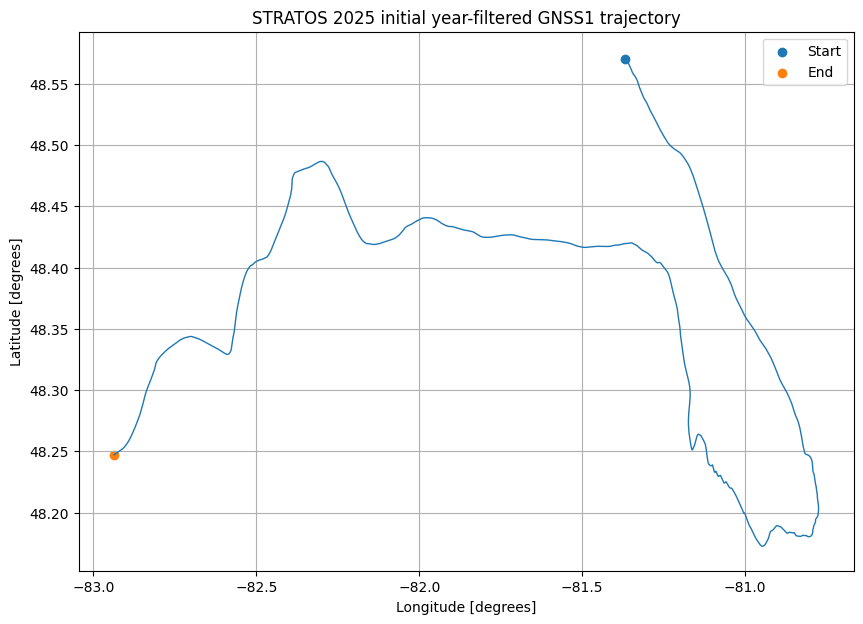

In [13]:
plot_2d_trajectory(
    trajectory_gnss1_initial_2025,
    title="STRATOS 2025 initial year-filtered GNSS1 trajectory",
)

## 11. Detect GNSS1 ellipsoid-height discontinuities

The analysis uses only 2025 rows in original acquisition order. Differences
are not calculated across backward timestamps or gaps longer than 10 seconds.

In [14]:
altitude_input_gnss1_2025 = (
    diagnostics_gnss1_2025[
        diagnostics_gnss1_2025["parsed_timestamp"].notna()
        & diagnostics_gnss1_2025["expected_year"]
    ]
    .sort_values("original_data_index")
    .reset_index(drop=True)
)

altitude_diagnostics_gnss1_2025 = (
    detect_altitude_discontinuities(
        altitude_input_gnss1_2025,
        step_threshold_m=1000,
        rate_threshold_mps=100,
        rolling_window=11,
        residual_threshold_m=1500,
        max_temporary_segment_samples=20,
        neighbor_tolerance_m=1000,
        max_gap_seconds=10,
    )
)

altitude_candidates_gnss1_2025 = (
    altitude_diagnostics_gnss1_2025[
        altitude_diagnostics_gnss1_2025[
            "altitude_anomaly_candidate"
        ]
    ].copy()
)

altitude_candidate_columns = [
    "original_data_index",
    "original_csv_row",
    "parsed_timestamp",
    "latitude_numeric",
    "longitude_numeric",
    "altitude_numeric",
    "time_step_s",
    "valid_consecutive_step",
    "altitude_step_m",
    "altitude_rate_mps",
    "rolling_altitude_median_m",
    "local_altitude_residual_m",
    "sudden_altitude_transition",
    "temporary_altitude_segment",
    "lat_lon_valid_flag",
]

print(
    "GNSS1 altitude anomaly candidates:",
    len(altitude_candidates_gnss1_2025),
)

display(
    altitude_candidates_gnss1_2025[
        altitude_candidate_columns
    ].head(300)
)

GNSS1 altitude anomaly candidates: 0


,original_data_index,original_csv_row,parsed_timestamp,latitude_numeric,longitude_numeric,altitude_numeric,time_step_s,valid_consecutive_step,altitude_step_m,altitude_rate_mps,rolling_altitude_median_m,local_altitude_residual_m,sudden_altitude_transition,temporary_altitude_segment,lat_lon_valid_flag


### Plot GNSS1 altitude and local-change candidates

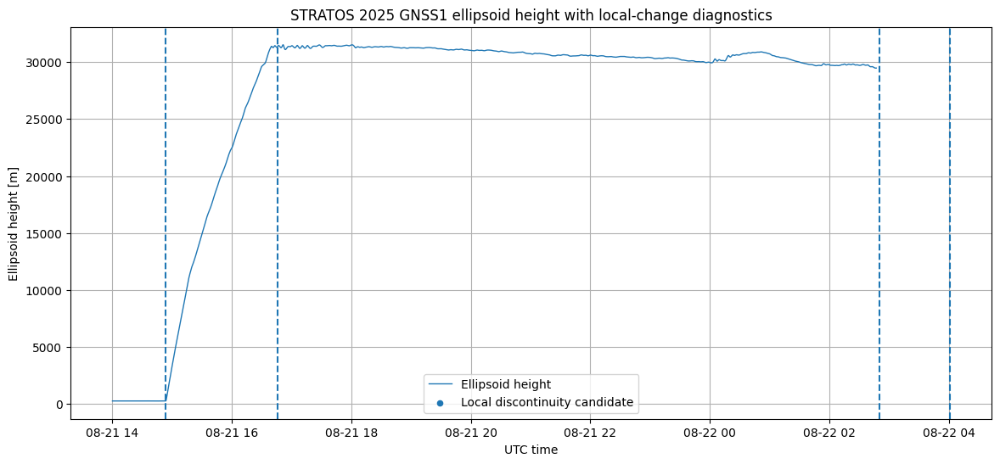

In [15]:
flagged_altitude_gnss1_2025 = (
    altitude_diagnostics_gnss1_2025[
        altitude_diagnostics_gnss1_2025[
            "altitude_anomaly_candidate"
        ]
    ]
)

plt.figure(figsize=(14, 6))
plt.plot(
    altitude_diagnostics_gnss1_2025["parsed_timestamp"],
    altitude_diagnostics_gnss1_2025["altitude_numeric"],
    linewidth=1,
    label="Ellipsoid height",
)
plt.scatter(
    flagged_altitude_gnss1_2025["parsed_timestamp"],
    flagged_altitude_gnss1_2025["altitude_numeric"],
    s=20,
    label="Local discontinuity candidate",
)

for _, event_row in FLIGHT_EVENTS[
    FLIGHT_EVENTS["event"].isin(
        [
            "Launch",
            "Start of pointing operations",
            "End of pointing operations",
            "Separation / descent begins",
        ]
    )
].iterrows():
    plt.axvline(
        event_row["timestamp"],
        linestyle="--",
    )

plt.xlabel("UTC time")
plt.ylabel("Ellipsoid height [m]")
plt.title(
    "STRATOS 2025 GNSS1 ellipsoid height with local-change diagnostics"
)
plt.legend()
plt.grid(True)
plt.show()

## 12. Detect GNSS1 spatial discontinuities and build the final trajectory

The initially cleaned trajectory is split whenever consecutive positions
differ by more than 100 km. The segment summary is displayed before selection.

In [16]:
(
    final_trajectory_gnss1_2025,
    segmented_trajectory_gnss1_2025,
    segment_summary_gnss1_2025,
    spatial_jump_candidates_gnss1_2025,
    selected_segment_gnss1_2025,
) = select_final_trajectory_segment(
    trajectory_gnss1_initial_2025,
    position_jump_threshold_m=POSITION_JUMP_THRESHOLD_M,
    auto_select_largest=AUTO_SELECT_LARGEST_SEGMENT,
)

print(
    "Consecutive GNSS1 position jumps greater than "
    f"{POSITION_JUMP_THRESHOLD_M / 1000:.0f} km:",
    len(spatial_jump_candidates_gnss1_2025),
)

display(
    spatial_jump_candidates_gnss1_2025[
        [
            "original_data_index",
            "original_csv_row",
            "timestamp",
            "latitude",
            "longitude",
            "altitude_m",
            "position_step_km",
            "time_step_s",
            "horizontal_speed_mps",
            "segment_id",
        ]
    ]
)

print("GNSS1 trajectory segment summary:")
display(segment_summary_gnss1_2025)

print("Selected GNSS1 segment ID:", selected_segment_gnss1_2025)
print("Initial cleaned rows:", len(trajectory_gnss1_initial_2025))
print("Final cleaned rows:", len(final_trajectory_gnss1_2025))
print("Final GNSS1 time range:")
print(final_trajectory_gnss1_2025["timestamp"].min())
print(final_trajectory_gnss1_2025["timestamp"].max())

assert not final_trajectory_gnss1_2025.empty
assert final_trajectory_gnss1_2025["timestamp"].dt.year.eq(YEAR).all()
assert ~(
    (final_trajectory_gnss1_2025["latitude"] == 0)
    & (final_trajectory_gnss1_2025["longitude"] == 0)
).any()

Consecutive GNSS1 position jumps greater than 100 km: 0


,original_data_index,original_csv_row,timestamp,latitude,longitude,altitude_m,position_step_km,time_step_s,horizontal_speed_mps,segment_id


GNSS1 trajectory segment summary:


,segment_id,rows,start_time,end_time,minimum_latitude,maximum_latitude,minimum_longitude,maximum_longitude,minimum_altitude,maximum_altitude
0,0,92063,2025-08-21 14:00:00+00:00,2025-08-22 02:47:11+00:00,48.17258,48.572502,-82.937015,-80.774451,254.595,31527.611


Selected GNSS1 segment ID: 0
Initial cleaned rows: 92063
Final cleaned rows: 92063
Final GNSS1 time range:
2025-08-21 14:00:00+00:00
2025-08-22 02:47:11+00:00


### Inspect rows surrounding every GNSS1 spatial jump

In [17]:
for bad_index in spatial_jump_candidates_gnss1_2025.index:
    start = max(0, bad_index - 6)
    end = min(
        len(segmented_trajectory_gnss1_2025) - 1,
        bad_index + 6,
    )

    print("\n" + "=" * 110)

    display(
        segmented_trajectory_gnss1_2025.loc[
            start:end,
            [
                "original_data_index",
                "original_csv_row",
                "timestamp",
                "latitude",
                "longitude",
                "altitude_m",
                "position_step_km",
                "time_step_s",
                "segment_id",
            ],
        ]
    )

## 13. Visualize the final cleaned GNSS1 trajectory

The same `final_trajectory_gnss1_2025` dataframe is used for both plots and
the final GNSS1 trajectory CSV export.

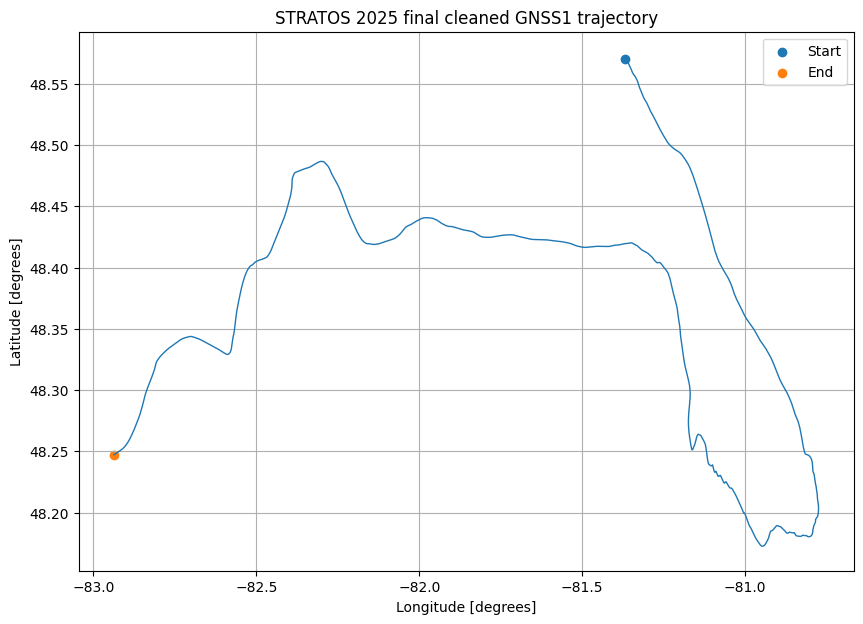

In [18]:
plot_2d_trajectory(
    final_trajectory_gnss1_2025,
    title="STRATOS 2025 final cleaned GNSS1 trajectory",
)

plot_3d_trajectory(
    final_trajectory_gnss1_2025,
    title="STRATOS 2025 final cleaned GNSS1 3D trajectory",
)

## 14. Clean and compare GNSS2

GNSS2 undergoes the same timestamp, coordinate, and spatial-continuity
processing as GNSS1.

GNSS2 timestamp counts by year:


,year,rows
0,2025,92063


Selected GNSS2 segment ID: 0


,segment_id,rows,start_time,end_time,minimum_latitude,maximum_latitude,minimum_longitude,maximum_longitude,minimum_altitude,maximum_altitude
0,0,92063,2025-08-21 14:00:00+00:00,2025-08-22 02:47:11+00:00,48.172575,48.572519,-82.937004,-80.774475,256.177,31524.815


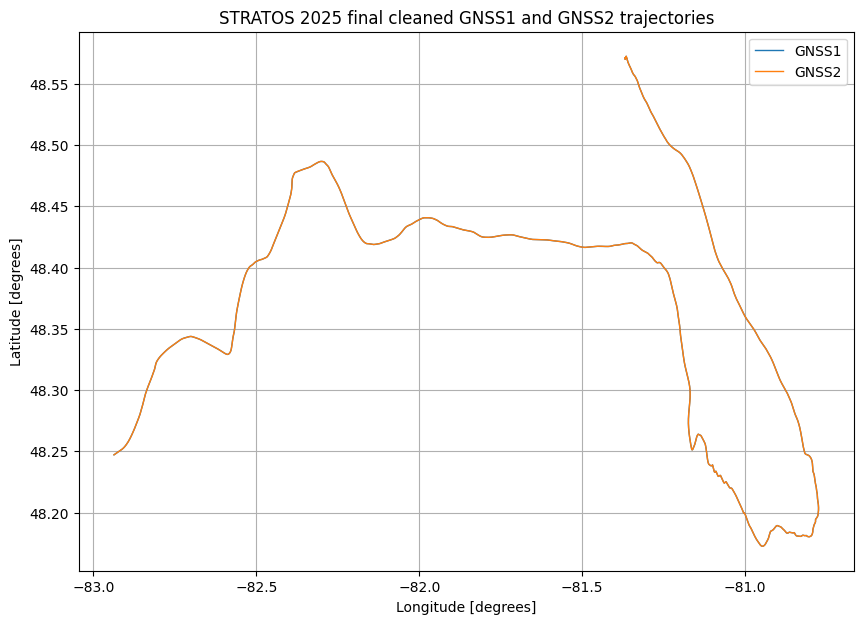

In [19]:
diagnostics_gnss2_2025, trajectory_gnss2_initial_2025 = (
    standardize_trajectory(
        gnss2,
        expected_year=YEAR,
        flight_date=FLIGHT_DATE,
        require_position_valid_flag=REQUIRE_POSITION_VALID_FLAG,
    )
)

gnss2_timestamp_anomalies_2025 = diagnostics_gnss2_2025[
    diagnostics_gnss2_2025["parsed_timestamp"].notna()
    & ~diagnostics_gnss2_2025["expected_year"]
].copy()

(
    final_trajectory_gnss2_2025,
    segmented_trajectory_gnss2_2025,
    segment_summary_gnss2_2025,
    spatial_jump_candidates_gnss2_2025,
    selected_segment_gnss2_2025,
) = select_final_trajectory_segment(
    trajectory_gnss2_initial_2025,
    position_jump_threshold_m=POSITION_JUMP_THRESHOLD_M,
    auto_select_largest=AUTO_SELECT_LARGEST_SEGMENT,
)

print("GNSS2 timestamp counts by year:")
display(
    diagnostics_gnss2_2025["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

print("Selected GNSS2 segment ID:", selected_segment_gnss2_2025)
display(segment_summary_gnss2_2025)

plt.figure(figsize=(10, 7))
plt.plot(
    final_trajectory_gnss1_2025["longitude"],
    final_trajectory_gnss1_2025["latitude"],
    linewidth=1,
    label="GNSS1",
)
plt.plot(
    final_trajectory_gnss2_2025["longitude"],
    final_trajectory_gnss2_2025["latitude"],
    linewidth=1,
    label="GNSS2",
)
plt.xlabel("Longitude [degrees]")
plt.ylabel("Latitude [degrees]")
plt.title(
    "STRATOS 2025 final cleaned GNSS1 and GNSS2 trajectories"
)
plt.legend()
plt.grid(True)
plt.show()

## 15. Parse and validate the 2025 NMEA dataset

The NMEA file has no header. The official dataset contains GPGGA records at
1 Hz from GNSS receiver 1.

In [20]:
if LOAD_NMEA:
    nmea_parsed_2025 = parse_gpgga_table(
        nmea_lines,
        flight_date=FLIGHT_DATE,
    )

    nmea_timestamp_anomalies_2025 = nmea_parsed_2025[
        nmea_parsed_2025["timestamp"].notna()
        & (nmea_parsed_2025["timestamp_year"] != YEAR)
    ].copy()

    nmea_invalid_or_unparsed_2025 = nmea_parsed_2025[
        nmea_parsed_2025["parse_error"].notna()
        | nmea_parsed_2025["timestamp"].isna()
        | (
            nmea_parsed_2025["checksum_valid"]
            .fillna(False)
            .eq(False)
        )
    ].copy()

    nmea_cleaned_2025 = (
        nmea_parsed_2025[
            nmea_parsed_2025["timestamp"].notna()
            & (nmea_parsed_2025["timestamp_year"] == YEAR)
            & nmea_parsed_2025["latitude"].between(-90, 90)
            & nmea_parsed_2025["longitude"].between(-180, 180)
            & ~(
                (nmea_parsed_2025["latitude"] == 0)
                & (nmea_parsed_2025["longitude"] == 0)
            )
            & (
                nmea_parsed_2025["checksum_valid"].isna()
                | nmea_parsed_2025["checksum_valid"].eq(True)
            )
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    print("Parsed NMEA rows:", len(nmea_parsed_2025))
    print("Cleaned NMEA rows:", len(nmea_cleaned_2025))
    print(
        "NMEA timestamp anomalies:",
        len(nmea_timestamp_anomalies_2025),
    )
    print(
        "NMEA invalid/unparsed rows:",
        len(nmea_invalid_or_unparsed_2025),
    )

    print("NMEA sentence types:")
    display(
        nmea_parsed_2025["sentence_type"]
        .value_counts(dropna=False)
        .rename_axis("sentence_type")
        .reset_index(name="rows")
    )

    print("NMEA checksum results:")
    display(
        nmea_parsed_2025["checksum_valid"]
        .value_counts(dropna=False)
        .rename_axis("checksum_valid")
        .reset_index(name="rows")
    )

    print("NMEA fix-quality distribution:")
    display(
        nmea_cleaned_2025["fix_quality"]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("fix_quality")
        .reset_index(name="rows")
    )

    print("NMEA sampling intervals:")
    display(
        sampling_interval_summary(
            nmea_cleaned_2025["timestamp"],
            maximum_gap_seconds=10,
        )
    )

    display(nmea_cleaned_2025.head(20))
else:
    nmea_parsed_2025 = pd.DataFrame()
    nmea_cleaned_2025 = pd.DataFrame()
    nmea_timestamp_anomalies_2025 = pd.DataFrame()
    nmea_invalid_or_unparsed_2025 = pd.DataFrame()

    print("NMEA file not loaded.")

Parsed NMEA rows: 91748
Cleaned NMEA rows: 45924
NMEA timestamp anomalies: 0
NMEA invalid/unparsed rows: 45824
NMEA sentence types:


,sentence_type,rows
0,GPGGA,45924
1,GPRMC,45824


NMEA checksum results:


,checksum_valid,rows
0,True,91748


NMEA fix-quality distribution:


,fix_quality,rows
0,0.0,231
1,1.0,45693


NMEA sampling intervals:


,metric,value
0,interval rows,45920.000000
1,minimum interval [s],1.000000
2,median interval [s],1.000000
3,mean interval [s],1.001437
4,95th percentile interval [s],1.000000
5,maximum included interval [s],10.000000
6,approximate median rate [Hz],1.000000


,original_data_index,raw_sentence,checksum_valid,sentence_type,parse_error,utc_time_raw,latitude,longitude,fix_quality,num_satellites,hdop,altitude_m,altitude_unit,geoid_separation_m,geoid_unit,differential_age_s,differential_station_id,timestamp,timestamp_year
0,0,"$GPGGA,140000.04,4834.20351,N,08122.06146,W,1,00,0.0,294.7,M,38.5,M,,*7B",True,GPGGA,NaN,140000.04,48.570059,-81.367691,1.0,0.0,0.0,294.7,M,38.5,M,NaN,,2025-08-21 14:00:00.040000+00:00,2025.0
1,2,"$GPGGA,140001.04,4834.20350,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*74",True,GPGGA,NaN,140001.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:01.040000+00:00,2025.0
2,4,"$GPGGA,140002.04,4834.20350,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*77",True,GPGGA,NaN,140002.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:02.040000+00:00,2025.0
3,6,"$GPGGA,140003.04,4834.20349,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*7E",True,GPGGA,NaN,140003.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:03.040000+00:00,2025.0
4,8,"$GPGGA,140004.04,4834.20348,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*78",True,GPGGA,NaN,140004.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:04.040000+00:00,2025.0
5,10,"$GPGGA,140005.04,4834.20347,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*76",True,GPGGA,NaN,140005.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:05.040000+00:00,2025.0
6,12,"$GPGGA,140006.04,4834.20348,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*7A",True,GPGGA,NaN,140006.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:06.040000+00:00,2025.0
7,14,"$GPGGA,140007.04,4834.20347,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*74",True,GPGGA,NaN,140007.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:07.040000+00:00,2025.0
8,16,"$GPGGA,140008.04,4834.20346,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*7A",True,GPGGA,NaN,140008.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:08.040000+00:00,2025.0
9,18,"$GPGGA,140009.04,4834.20347,N,08122.06146,W,1,00,0.0,294.8,M,38.5,M,,*7A",True,GPGGA,NaN,140009.04,48.570058,-81.367691,1.0,0.0,0.0,294.8,M,38.5,M,NaN,,2025-08-21 14:00:09.040000+00:00,2025.0


### Compare cleaned NMEA positions with cleaned GNSS1 positions

In [ ]:
if LOAD_NMEA and not nmea_cleaned_2025.empty:
    nmea_for_comparison = (
        nmea_cleaned_2025[
            [
                "timestamp",
                "latitude",
                "longitude",
                "altitude_m",
                "fix_quality",
                "num_satellites",
                "hdop",
            ]
        ]
        .rename(
            columns={
                "latitude": "nmea_latitude",
                "longitude": "nmea_longitude",
                "altitude_m": "nmea_altitude_m",
            }
        )
        .copy()
    )

    gnss1_for_comparison = (
        final_trajectory_gnss1_2025[
            [
                "timestamp",
                "latitude",
                "longitude",
                "altitude_m",
            ]
        ]
        .rename(
            columns={
                "timestamp": "gnss1_timestamp",
                "latitude": "gnss1_latitude",
                "longitude": "gnss1_longitude",
                "altitude_m": "gnss1_altitude_m",
            }
        )
        .copy()
    )

    # merge_asof requires both merge keys to have
    # exactly the same datetime dtype.
    nmea_for_comparison["timestamp"] = (
        pd.to_datetime(
            nmea_for_comparison["timestamp"],
            utc=True,
            errors="coerce",
        )
        .astype("datetime64[ns, UTC]")
    )

    gnss1_for_comparison["gnss1_timestamp"] = (
        pd.to_datetime(
            gnss1_for_comparison["gnss1_timestamp"],
            utc=True,
            errors="coerce",
        )
        .astype("datetime64[ns, UTC]")
    )

    # Remove invalid timestamps and sort both merge keys.
    nmea_for_comparison = (
        nmea_for_comparison
        .dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    gnss1_for_comparison = (
        gnss1_for_comparison
        .dropna(subset=["gnss1_timestamp"])
        .sort_values("gnss1_timestamp")
        .reset_index(drop=True)
    )

    nmea_gnss1_comparison_2025 = pd.merge_asof(
        nmea_for_comparison,
        gnss1_for_comparison,
        left_on="timestamp",
        right_on="gnss1_timestamp",
        direction="nearest",
        tolerance=pd.Timedelta(seconds=1),
    )

    # Calculate the time difference between matched records.
    nmea_gnss1_comparison_2025["time_difference_s"] = (
        (
            nmea_gnss1_comparison_2025["timestamp"]
            - nmea_gnss1_comparison_2025["gnss1_timestamp"]
        )
        .abs()
        .dt.total_seconds()
    )

    def haversine_between_points_m(
        latitude_1: pd.Series,
        longitude_1: pd.Series,
        latitude_2: pd.Series,
        longitude_2: pd.Series,
    ) -> np.ndarray:
        """Calculate row-by-row distance between coordinate pairs."""

        lat1 = np.radians(
            pd.to_numeric(
                latitude_1,
                errors="coerce",
            ).to_numpy(dtype=float)
        )

        lon1 = np.radians(
            pd.to_numeric(
                longitude_1,
                errors="coerce",
            ).to_numpy(dtype=float)
        )

        lat2 = np.radians(
            pd.to_numeric(
                latitude_2,
                errors="coerce",
            ).to_numpy(dtype=float)
        )

        lon2 = np.radians(
            pd.to_numeric(
                longitude_2,
                errors="coerce",
            ).to_numpy(dtype=float)
        )

        delta_latitude = lat2 - lat1
        delta_longitude = lon2 - lon1

        a = (
            np.sin(delta_latitude / 2) ** 2
            + np.cos(lat1)
            * np.cos(lat2)
            * np.sin(delta_longitude / 2) ** 2
        )

        # Avoid small floating-point values outside [0, 1].
        a = np.clip(a, 0, 1)

        return (
            2
            * EARTH_RADIUS_M
            * np.arcsin(np.sqrt(a))
        )

    nmea_gnss1_comparison_2025[
        "horizontal_difference_m"
    ] = haversine_between_points_m(
        nmea_gnss1_comparison_2025["nmea_latitude"],
        nmea_gnss1_comparison_2025["nmea_longitude"],
        nmea_gnss1_comparison_2025["gnss1_latitude"],
        nmea_gnss1_comparison_2025["gnss1_longitude"],
    )

    nmea_gnss1_comparison_2025[
        "altitude_difference_m"
    ] = (
        nmea_gnss1_comparison_2025["nmea_altitude_m"]
        - nmea_gnss1_comparison_2025["gnss1_altitude_m"]
    )

    matched_comparison = (
        nmea_gnss1_comparison_2025
        .dropna(
            subset=[
                "gnss1_latitude",
                "gnss1_longitude",
            ]
        )
        .copy()
    )

    print(
        "NMEA timestamp dtype:",
        nmea_for_comparison["timestamp"].dtype,
    )

    print(
        "GNSS1 timestamp dtype:",
        gnss1_for_comparison["gnss1_timestamp"].dtype,
    )

    print(
        "Matched NMEA/GNSS1 rows:",
        len(matched_comparison),
    )

    display(
        matched_comparison[
            [
                "time_difference_s",
                "horizontal_difference_m",
                "altitude_difference_m",
            ]
        ].describe()
    )

    display(matched_comparison.head(20))

else:
    nmea_gnss1_comparison_2025 = pd.DataFrame()
    matched_comparison = pd.DataFrame()

    print("No cleaned NMEA data available for comparison.")

MergeError: incompatible merge keys [0] datetime64[ns, UTC] and datetime64[us, UTC], must be the same type

## 16. Inspect and clean IMU temperature and pressure

Only 2025 timestamps are plotted and exported. Timestamp anomalies remain in
a separate table.

IMU timestamp counts by year:


,year,rows
0,2025,46032


Available IMU fields: {'Minimum temperature [°C]': 'Min Temp', 'Maximum temperature [°C]': 'Max Temp', 'Mean temperature [°C]': 'Mean Temp', 'Pressure [mbar]': 'Pressure'}


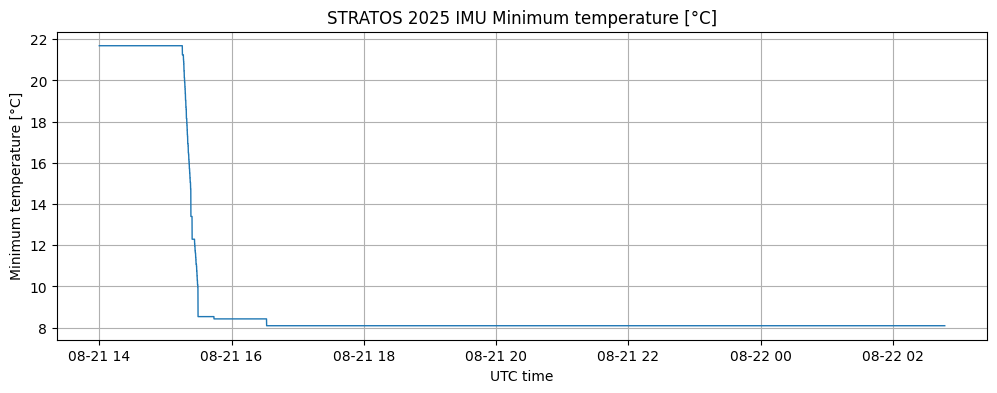

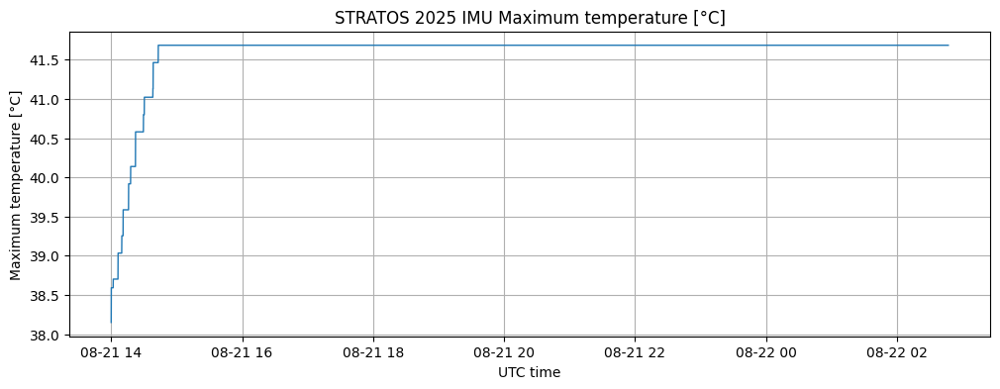

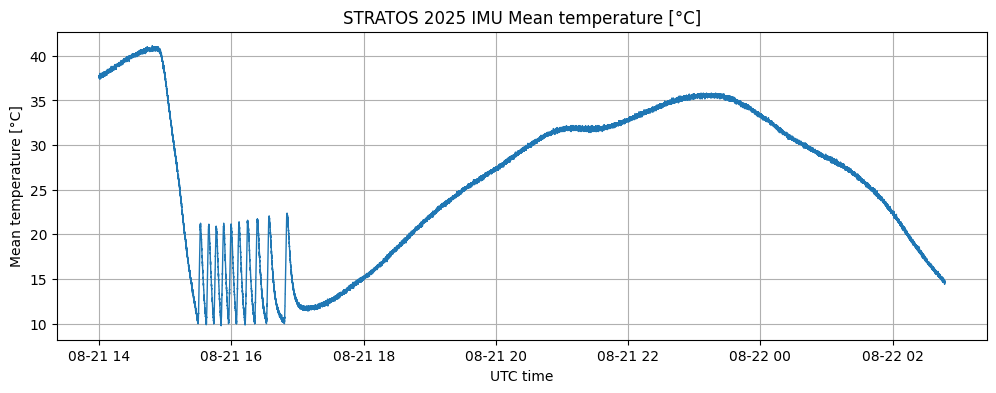

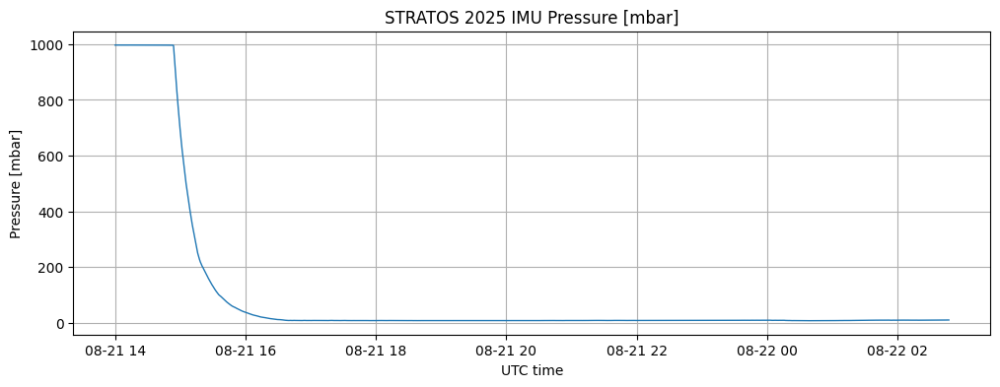

In [22]:
(
    imu_diagnostics_2025,
    imu_timestamp_anomalies_2025,
    imu_2025,
) = prepare_campaign_timeseries(
    imu,
    expected_year=YEAR,
    flight_date=FLIGHT_DATE,
)

print("IMU timestamp counts by year:")
display(
    imu_diagnostics_2025["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

imu_fields = {
    "Minimum temperature [°C]": [
        "Min Temp",
        "Minimum Temp",
    ],
    "Maximum temperature [°C]": [
        "Max Temp",
        "Maximum Temp",
    ],
    "Mean temperature [°C]": [
        "Mean Temp",
        "Mean Temperature",
    ],
    "Pressure [mbar]": ["Pressure"],
}

imu_plot_columns: dict[str, str] = {}

for label, candidates in imu_fields.items():
    column = find_column(
        imu_2025,
        candidates,
        required=False,
    )

    if column is not None:
        imu_plot_columns[label] = column
        imu_2025[column] = numeric(imu_2025[column])

print("Available IMU fields:", imu_plot_columns)

for label, column in imu_plot_columns.items():
    plot_data = imu_2025[
        ["parsed_timestamp", column]
    ].dropna()

    plt.figure(figsize=(12, 4))
    plt.plot(
        plot_data["parsed_timestamp"],
        plot_data[column],
        linewidth=1,
    )
    plt.xlabel("UTC time")
    plt.ylabel(label)
    plt.title(f"STRATOS 2025 IMU {label}")
    plt.grid(True)
    plt.show()

## 17. Inspect and clean track angle with pointing-event context

Only 2025 timestamps are plotted and exported. The track-angle validity flag
is reported separately.

Track-angle timestamp counts by year:


,year,rows
0,2025,46032


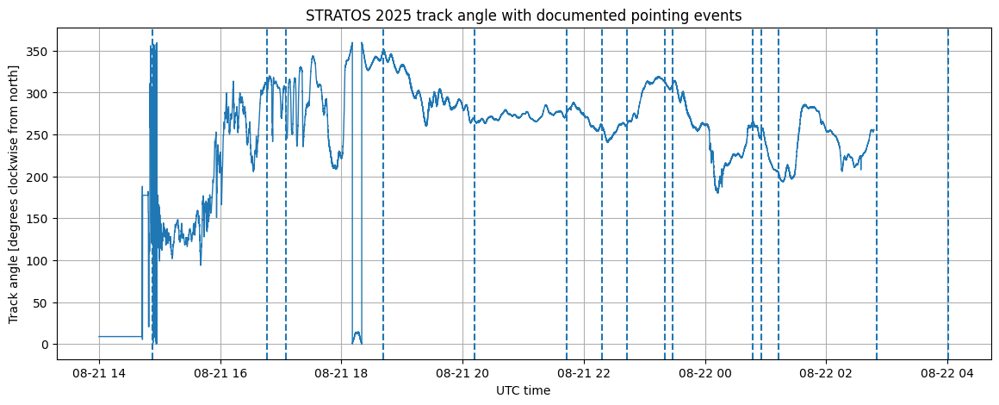

,validity value,rows
0,1,42719
1,0,3313


In [23]:
(
    track_diagnostics_2025,
    track_timestamp_anomalies_2025,
    track_2025,
) = prepare_campaign_timeseries(
    track,
    expected_year=YEAR,
    flight_date=FLIGHT_DATE,
)

track_angle_col = find_column(
    track_2025,
    ["Track Angle"],
    required=True,
)
track_valid_col = find_column(
    track_2025,
    ["Track Angle Valid"],
    required=False,
)

track_2025["track_angle_numeric"] = numeric(
    track_2025[track_angle_col]
)

print("Track-angle timestamp counts by year:")
display(
    track_diagnostics_2025["timestamp_year"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year")
    .reset_index(name="rows")
)

plt.figure(figsize=(14, 5))
plt.plot(
    track_2025["parsed_timestamp"],
    track_2025["track_angle_numeric"],
    linewidth=1,
)

for _, event_row in FLIGHT_EVENTS.iterrows():
    plt.axvline(
        event_row["timestamp"],
        linestyle="--",
    )

plt.xlabel("UTC time")
plt.ylabel("Track angle [degrees clockwise from north]")
plt.title(
    "STRATOS 2025 track angle with documented pointing events"
)
plt.grid(True)
plt.show()

if track_valid_col is not None:
    display(
        track_2025[track_valid_col]
        .value_counts(dropna=False)
        .rename_axis("validity value")
        .reset_index(name="rows")
    )

## 18. Index and inspect the 2025 onboard images

Camera `0` is the nadir-facing camera. The index is built from image filenames;
the images themselves are downloaded only for the selected examples.

In [24]:
image_index_2025 = pd.DataFrame(
    columns=[
        "camera_id",
        "camera_label",
        "timestamp",
        "filename",
        "url",
    ]
)

if INDEX_IMAGES:
    try:
        image_index_2025 = index_image_directory(
            IMAGE_BASE_URL
        )

        print("Indexed images:", len(image_index_2025))

        if not image_index_2025.empty:
            display(
                image_index_2025["camera_label"]
                .value_counts(dropna=False)
                .rename_axis("camera")
                .reset_index(name="images")
            )

            print("Image time range:")
            print(image_index_2025["timestamp"].min())
            print(image_index_2025["timestamp"].max())

            display(image_index_2025.head(20))
    except Exception as error:
        print("Image indexing was unavailable:")
        print(type(error).__name__, error)
else:
    print("Set INDEX_IMAGES = True to index the image directory.")

Indexed images: 181


,camera,images
0,Nadir,181


Image time range:
2025-08-21 14:46:38+00:00
2025-08-22 02:46:38+00:00


,camera_id,camera_label,timestamp,filename,url
0,0,Nadir,2025-08-21 14:46:38+00:00,0_20250821_144638.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_144638.jpg
1,0,Nadir,2025-08-21 14:50:38+00:00,0_20250821_145038.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_145038.jpg
2,0,Nadir,2025-08-21 14:54:38+00:00,0_20250821_145438.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_145438.jpg
3,0,Nadir,2025-08-21 14:58:38+00:00,0_20250821_145838.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_145838.jpg
4,0,Nadir,2025-08-21 15:02:38+00:00,0_20250821_150238.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_150238.jpg
5,0,Nadir,2025-08-21 15:06:38+00:00,0_20250821_150638.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_150638.jpg
6,0,Nadir,2025-08-21 15:10:38+00:00,0_20250821_151038.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_151038.jpg
7,0,Nadir,2025-08-21 15:14:38+00:00,0_20250821_151438.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_151438.jpg
8,0,Nadir,2025-08-21 15:18:38+00:00,0_20250821_151838.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_151838.jpg
9,0,Nadir,2025-08-21 15:22:38+00:00,0_20250821_152238.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_152238.jpg


### Find and display images nearest to major flight events

,event,camera_id,camera_label,timestamp,filename,url,target_timestamp,time_difference_s
0,Launch,0,Nadir,2025-08-21 14:54:38+00:00,0_20250821_145438.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_145438.jpg,2025-08-21 14:53:00+00:00,98.0
1,Start of pointing operations,0,Nadir,2025-08-21 16:46:38+00:00,0_20250821_164638.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250821_164638.jpg,2025-08-21 16:46:00+00:00,38.0
2,End of pointing operations,0,Nadir,2025-08-22 02:46:38+00:00,0_20250822_024638.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250822_024638.jpg,2025-08-22 02:50:00+00:00,202.0
3,Separation / descent begins,0,Nadir,2025-08-22 02:46:38+00:00,0_20250822_024638.jpg,https://donnees-data.asc-csa.gc.ca/users/OpenData_DonneesOuvertes/pub/STRATOS/STRATOS/uprism_images_2025/0_20250822_024638.jpg,2025-08-22 04:01:00+00:00,4462.0


Launch | image: 0_20250821_145438.jpg | difference [s]: 98.0


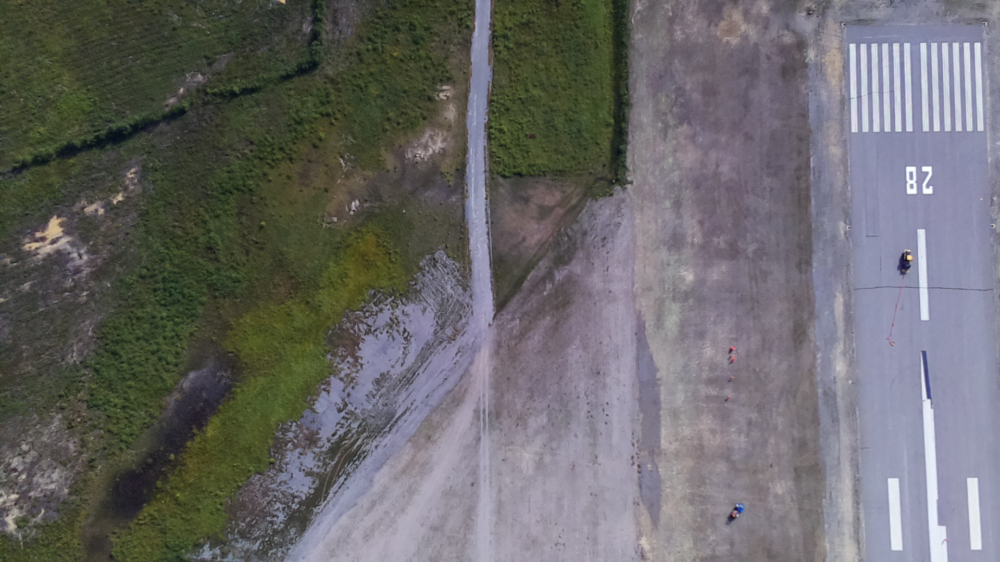

Start of pointing operations | image: 0_20250821_164638.jpg | difference [s]: 38.0


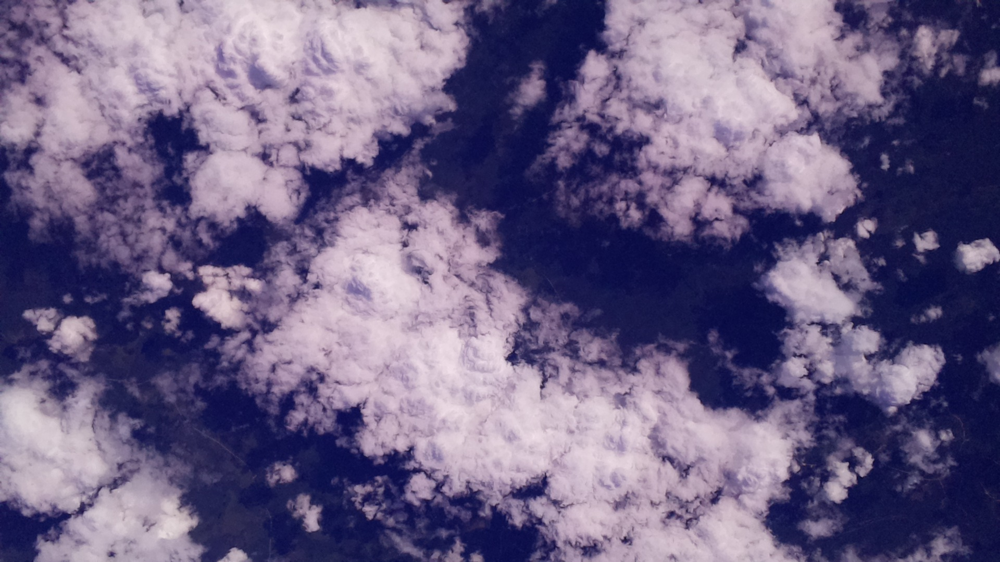

End of pointing operations | image: 0_20250822_024638.jpg | difference [s]: 202.0


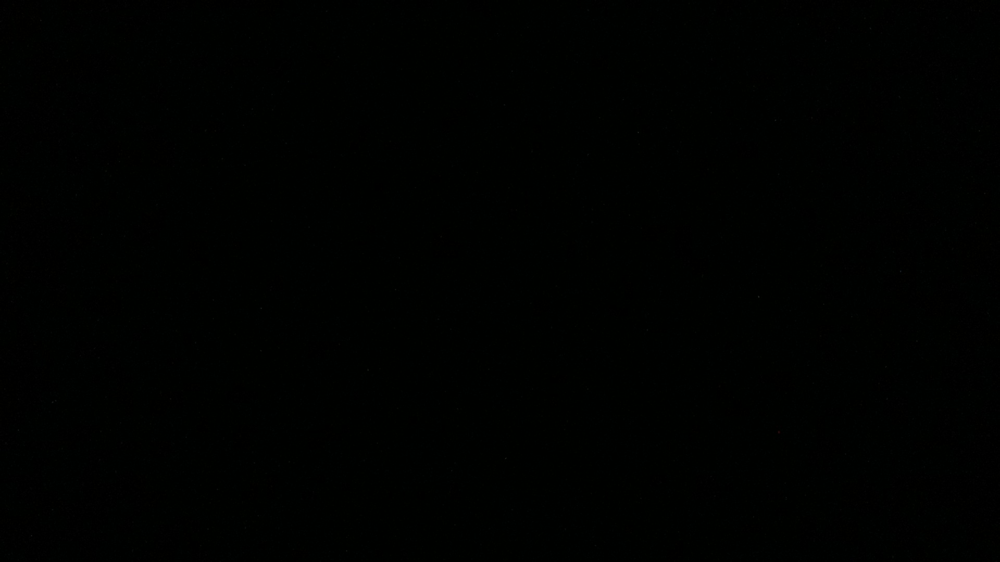

Separation / descent begins | image: 0_20250822_024638.jpg | difference [s]: 4462.0


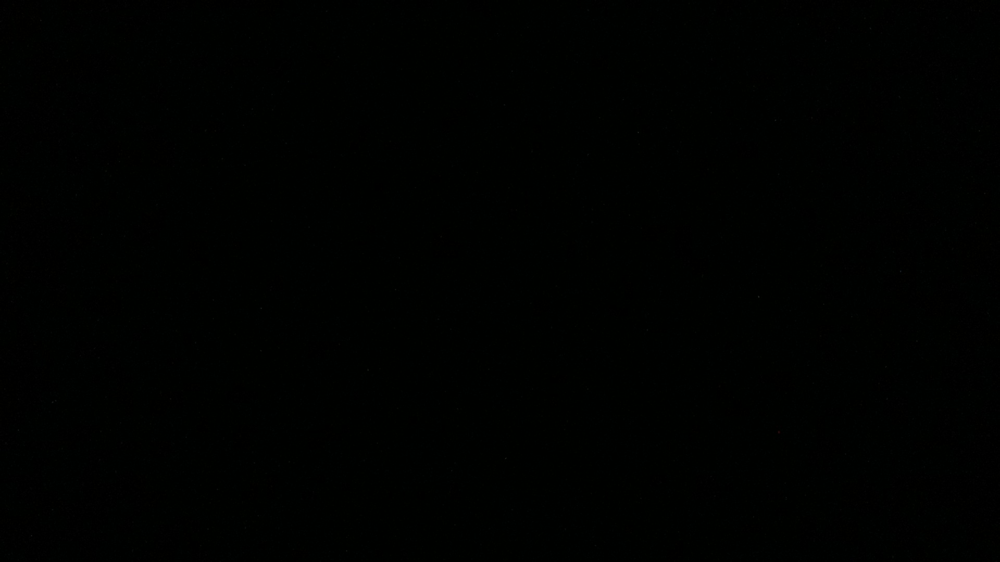

In [25]:
major_event_times = FLIGHT_EVENTS[
    FLIGHT_EVENTS["event"].isin(
        [
            "Launch",
            "Start of pointing operations",
            "End of pointing operations",
            "Separation / descent begins",
        ]
    )
][["event", "timestamp"]].copy()

if not image_index_2025.empty:
    nearest_event_images_2025 = nearest_image_rows(
        image_index_2025,
        major_event_times["timestamp"].tolist(),
    )

    nearest_event_images_2025.insert(
        0,
        "event",
        major_event_times["event"].to_list(),
    )

    display(nearest_event_images_2025)

    DISPLAY_EVENT_IMAGES = True

    if DISPLAY_EVENT_IMAGES:
        for _, image_row in nearest_event_images_2025.iterrows():
            print(
                image_row["event"],
                "| image:",
                image_row["filename"],
                "| difference [s]:",
                image_row["time_difference_s"],
            )

            try:
                display(
                    download_image(image_row["url"])
                )
            except Exception as error:
                print(
                    "Could not download image:",
                    type(error).__name__,
                    error,
                )
else:
    nearest_event_images_2025 = pd.DataFrame()
    print("No image index is available.")

## 19. 25 Hz estimation-filter trajectory

Enable `LOAD_EF_25HZ` in the configuration section and rerun the loading cells.
The resulting trajectory is cleaned using the same year, coordinate, and
spatial-continuity framework.

In [26]:
if LOAD_EF_25HZ:
    ef_25hz = tables["ef_25hz"]

    diagnostics_ef25_2025, trajectory_ef25_initial_2025 = (
        standardize_trajectory(
            ef_25hz,
            expected_year=YEAR,
            flight_date=FLIGHT_DATE,
            require_position_valid_flag=False,
        )
    )

    ef25_timestamp_anomalies_2025 = diagnostics_ef25_2025[
        diagnostics_ef25_2025["parsed_timestamp"].notna()
        & ~diagnostics_ef25_2025["expected_year"]
    ].copy()

    (
        final_trajectory_ef25_2025,
        segmented_trajectory_ef25_2025,
        segment_summary_ef25_2025,
        spatial_jump_candidates_ef25_2025,
        selected_segment_ef25_2025,
    ) = select_final_trajectory_segment(
        trajectory_ef25_initial_2025,
        position_jump_threshold_m=POSITION_JUMP_THRESHOLD_M,
        auto_select_largest=AUTO_SELECT_LARGEST_SEGMENT,
    )

    print("EF 25 Hz timestamp counts by year:")
    display(
        diagnostics_ef25_2025["timestamp_year"]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("year")
        .reset_index(name="rows")
    )

    display(segment_summary_ef25_2025)

    plot_2d_trajectory(
        final_trajectory_ef25_2025,
        title="STRATOS 2025 final cleaned EF 25 Hz trajectory",
    )
else:
    diagnostics_ef25_2025 = pd.DataFrame()
    trajectory_ef25_initial_2025 = pd.DataFrame()
    final_trajectory_ef25_2025 = pd.DataFrame()
    ef25_timestamp_anomalies_2025 = pd.DataFrame()
    spatial_jump_candidates_ef25_2025 = pd.DataFrame()
    segment_summary_ef25_2025 = pd.DataFrame()

    print(
        "EF 25 Hz file not loaded. Set LOAD_EF_25HZ = True "
        "and rerun the loading cells."
    )

EF 25 Hz file not loaded. Set LOAD_EF_25HZ = True and rerun the loading cells.


## 20. 1 Hz supplementary estimation-filter inspection

The EF 1 Hz file contains supplementary filter status, uncertainty, bias,
gravity, aiding, and dual-antenna information rather than the core
latitude/longitude trajectory fields.

In [27]:
if LOAD_EF_1HZ:
    ef_1hz = tables["ef_1hz"]

    (
        ef1_diagnostics_2025,
        ef1_timestamp_anomalies_2025,
        ef1_2025,
    ) = prepare_campaign_timeseries(
        ef_1hz,
        expected_year=YEAR,
        flight_date=FLIGHT_DATE,
    )

    print("EF 1 Hz timestamp counts by year:")
    display(
        ef1_diagnostics_2025["timestamp_year"]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("year")
        .reset_index(name="rows")
    )

    display(missing_value_summary(ef1_2025).head(40))
    display(ef1_2025.head(20))
else:
    ef1_diagnostics_2025 = pd.DataFrame()
    ef1_timestamp_anomalies_2025 = pd.DataFrame()
    ef1_2025 = pd.DataFrame()

    print(
        "EF 1 Hz file not loaded. Set LOAD_EF_1HZ = True "
        "and rerun the loading cells."
    )

EF 1 Hz file not loaded. Set LOAD_EF_1HZ = True and rerun the loading cells.


## 21. Export final cleaned data and diagnostics

The final GNSS1 trajectory CSV is created from
`final_trajectory_gnss1_2025`, the same dataframe used in its final plots.
Optional EF exports are added only when those files were loaded.

In [29]:
OUTPUT_DIR = Path("tutorial_outputs_2025")
OUTPUT_DIR.mkdir(exist_ok=True)

export_files = {
    "gnss1_final_trajectory": (
        final_trajectory_gnss1_2025,
        OUTPUT_DIR / "gnss1_final_cleaned_trajectory_2025.csv",
    ),
    "gnss1_timestamp_anomalies": (
        gnss1_timestamp_anomalies_2025,
        OUTPUT_DIR / "gnss1_timestamp_anomalies_2025.csv",
    ),
    "gnss1_altitude_candidates": (
        altitude_candidates_gnss1_2025,
        OUTPUT_DIR / "gnss1_altitude_anomaly_candidates_2025.csv",
    ),
    "gnss1_spatial_jump_candidates": (
        spatial_jump_candidates_gnss1_2025,
        OUTPUT_DIR / "gnss1_spatial_jump_candidates_2025.csv",
    ),
    "gnss1_trajectory_segments": (
        segment_summary_gnss1_2025,
        OUTPUT_DIR / "gnss1_trajectory_segments_2025.csv",
    ),
    "gnss2_final_trajectory": (
        final_trajectory_gnss2_2025,
        OUTPUT_DIR / "gnss2_final_cleaned_trajectory_2025.csv",
    ),
    "gnss2_timestamp_anomalies": (
        gnss2_timestamp_anomalies_2025,
        OUTPUT_DIR / "gnss2_timestamp_anomalies_2025.csv",
    ),
    "gnss2_spatial_jump_candidates": (
        spatial_jump_candidates_gnss2_2025,
        OUTPUT_DIR / "gnss2_spatial_jump_candidates_2025.csv",
    ),
    "gnss2_trajectory_segments": (
        segment_summary_gnss2_2025,
        OUTPUT_DIR / "gnss2_trajectory_segments_2025.csv",
    ),
    "imu_cleaned": (
        imu_2025,
        OUTPUT_DIR / "imu_cleaned_2025.csv",
    ),
    "imu_timestamp_anomalies": (
        imu_timestamp_anomalies_2025,
        OUTPUT_DIR / "imu_timestamp_anomalies_2025.csv",
    ),
    "track_cleaned": (
        track_2025,
        OUTPUT_DIR / "track_angle_cleaned_2025.csv",
    ),
    "track_timestamp_anomalies": (
        track_timestamp_anomalies_2025,
        OUTPUT_DIR / "track_angle_timestamp_anomalies_2025.csv",
    ),
    "flight_events": (
        FLIGHT_EVENTS,
        OUTPUT_DIR / "flight_events_2025.csv",
    ),
    "image_index": (
        image_index_2025,
        OUTPUT_DIR / "image_index_2025.csv",
    ),
    "nearest_event_images": (
        nearest_event_images_2025,
        OUTPUT_DIR / "nearest_event_images_2025.csv",
    ),
}

def add_optional_export(
    export_dictionary: dict,
    *,
    export_label: str,
    variable_name: str,
    filename: str,
) -> None:
    """Add an optional dataframe export only when it exists."""

    frame = globals().get(variable_name)

    if isinstance(frame, pd.DataFrame):
        export_dictionary[export_label] = (
            frame,
            OUTPUT_DIR / filename,
        )
    else:
        print(
            f"Skipping {export_label}: "
            f"{variable_name} has not been created."
        )


if LOAD_NMEA:
    nmea_export_definitions = [
        (
            "nmea_parsed",
            "nmea_parsed_2025",
            "nmea_parsed_2025.csv",
        ),
        (
            "nmea_cleaned",
            "nmea_cleaned_2025",
            "nmea_cleaned_2025.csv",
        ),
        (
            "nmea_timestamp_anomalies",
            "nmea_timestamp_anomalies_2025",
            "nmea_timestamp_anomalies_2025.csv",
        ),
        (
            "nmea_invalid_or_unparsed",
            "nmea_invalid_or_unparsed_2025",
            "nmea_invalid_or_unparsed_2025.csv",
        ),
        (
            "nmea_gnss1_comparison",
            "nmea_gnss1_comparison_2025",
            "nmea_gnss1_comparison_2025.csv",
        ),
    ]

    for label, variable, filename in nmea_export_definitions:
        add_optional_export(
            export_files,
            export_label=label,
            variable_name=variable,
            filename=filename,
        )


if LOAD_EF_25HZ:
    ef25_export_definitions = [
        (
            "ef25_final_trajectory",
            "final_trajectory_ef25_2025",
            "ef25_final_cleaned_trajectory_2025.csv",
        ),
        (
            "ef25_timestamp_anomalies",
            "ef25_timestamp_anomalies_2025",
            "ef25_timestamp_anomalies_2025.csv",
        ),
        (
            "ef25_spatial_jump_candidates",
            "spatial_jump_candidates_ef25_2025",
            "ef25_spatial_jump_candidates_2025.csv",
        ),
        (
            "ef25_trajectory_segments",
            "segment_summary_ef25_2025",
            "ef25_trajectory_segments_2025.csv",
        ),
    ]

    for label, variable, filename in ef25_export_definitions:
        add_optional_export(
            export_files,
            export_label=label,
            variable_name=variable,
            filename=filename,
        )


if LOAD_EF_1HZ:
    ef1_export_definitions = [
        (
            "ef1_cleaned",
            "ef1_2025",
            "ef1_cleaned_2025.csv",
        ),
        (
            "ef1_timestamp_anomalies",
            "ef1_timestamp_anomalies_2025",
            "ef1_timestamp_anomalies_2025.csv",
        ),
    ]

    for label, variable, filename in ef1_export_definitions:
        add_optional_export(
            export_files,
            export_label=label,
            variable_name=variable,
            filename=filename,
        )

export_summary_rows = []

for label, (frame, path) in export_files.items():
    frame.to_csv(path, index=False)

    export_summary_rows.append(
        {
            "export": label,
            "rows": len(frame),
            "columns": len(frame.columns),
            "path": str(path.resolve()),
        }
    )

export_summary_2025 = pd.DataFrame(export_summary_rows)
display(export_summary_2025)

print("Saved files to:", OUTPUT_DIR.resolve())

Skipping nmea_gnss1_comparison: nmea_gnss1_comparison_2025 has not been created.


,export,rows,columns,path
0,gnss1_final_trajectory,92063,7,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss1_final_cleaned_trajectory_202...
1,gnss1_timestamp_anomalies,0,78,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss1_timestamp_anomalies_2025.csv
2,gnss1_altitude_candidates,0,88,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss1_altitude_anomaly_candidates_...
3,gnss1_spatial_jump_candidates,0,13,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss1_spatial_jump_candidates_2025...
4,gnss1_trajectory_segments,1,10,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss1_trajectory_segments_2025.csv
5,gnss2_final_trajectory,92063,7,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss2_final_cleaned_trajectory_202...
6,gnss2_timestamp_anomalies,0,78,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss2_timestamp_anomalies_2025.csv
7,gnss2_spatial_jump_candidates,0,13,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss2_spatial_jump_candidates_2025...
8,gnss2_trajectory_segments,1,10,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\gnss2_trajectory_segments_2025.csv
9,imu_cleaned,46032,31,C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025\imu_cleaned_2025.csv


Saved files to: C:\Users\ychoi\OneDrive - CSA ASC\Desktop\Work\FSDH\DATACENTER\Dataset_Tutorial\notebooks\tutorial_outputs_2025


## 22. Final consistency checks

These checks confirm that the final GNSS1 trajectory used for plotting and
export contains only 2025 timestamps, excludes `(0°, 0°)`, and matches the
exported row count. The other cleaned time-series exports are checked as well.

In [30]:
final_gnss1_export_path = (
    OUTPUT_DIR / "gnss1_final_cleaned_trajectory_2025.csv"
)
final_gnss1_export_check = pd.read_csv(
    final_gnss1_export_path
)

assert (
    len(final_gnss1_export_check)
    == len(final_trajectory_gnss1_2025)
)
assert (
    final_trajectory_gnss1_2025["timestamp"]
    .dt.year
    .eq(YEAR)
    .all()
)
assert ~(
    (final_trajectory_gnss1_2025["latitude"] == 0)
    & (final_trajectory_gnss1_2025["longitude"] == 0)
).any()

assert final_trajectory_gnss2_2025["timestamp"].dt.year.eq(
    YEAR
).all()

assert ~(
    (final_trajectory_gnss2_2025["latitude"] == 0)
    & (final_trajectory_gnss2_2025["longitude"] == 0)
).any()

for label, frame in {
    "IMU": imu_2025,
    "track angle": track_2025,
}.items():
    assert frame["parsed_timestamp"].dt.year.eq(YEAR).all(), label

if LOAD_NMEA and not nmea_cleaned_2025.empty:
    assert nmea_cleaned_2025["timestamp"].dt.year.eq(YEAR).all()
    assert ~(
        (nmea_cleaned_2025["latitude"] == 0)
        & (nmea_cleaned_2025["longitude"] == 0)
    ).any()

if not image_index_2025.empty:
    assert image_index_2025["timestamp"].dt.year.eq(YEAR).all()
    assert image_index_2025["camera_id"].eq("0").all()

print("Final consistency checks passed.")
print(
    "Final GNSS1 trajectory rows:",
    len(final_trajectory_gnss1_2025),
)
print(
    "Exported GNSS1 trajectory rows:",
    len(final_gnss1_export_check),
)

Final consistency checks passed.
Final GNSS1 trajectory rows: 92063
Exported GNSS1 trajectory rows: 92063


## Conclusions

- Raw source tables remain unchanged for traceability.
- Timestamp years are reported before campaign-year filtering.
- `(0°, 0°)` placeholders do not define the flight origin.
- GNSS1 and GNSS2 use the same timestamp, coordinate, and
  spatial-continuity framework.
- NMEA records are parsed from the headerless file, checksum-checked, and
  compared with GNSS1.
- IMU and track-angle plots use only 2025 timestamps.
- Pointing events are retained as a campaign timeline and shown with the track
  angle.
- The 2025 onboard images are indexed from filenames, with camera `0` treated
  as the nadir-facing camera.
- EF 25 Hz and EF 1 Hz remain optional to keep the default run manageable.
- `final_trajectory_gnss1_2025` is used consistently for the final GNSS1 2D
  plot, final 3D plot, and final GNSS1 trajectory CSV export.
- All anomaly tables, NMEA validation results, image indexes, and trajectory
  segment summaries remain available for scientific review and audit.